# ****EVALUATION****

<p align="center">
    <img src="../xLain-Lain/img/e_1_1.png" alt="Evaluation" witdh="100" height="500">
</p>

### ****Daftar Isi****

1. Persiapan dan Pemuatan Model Final
2. Evaluasi Akhir terhadap Baseline (RMSE, MAE, QLIKE, Interval Kepercayaan)
3. Kalibrasi dan Kinerja menurut Rezim
4. XAI Global: SHAP *Summary*, Kontribusi Relatif, *Dependence Plot*
5. Kestabilan Penjelasan: Antar Fold dan terhadap *Permutation Importance*
6. XAI Lokal: Tanggal Berisiko Tinggi pada Data Uji
7. Analisis Kesalahan Berbasis XAI
8. Sistem Peringatan Dini (Hijau / Kuning / Merah)
9. Ringkasan Hasil dan Kesimpulan

---

### ****1. Persiapan dan Pemuatan Model Final****

Sel-sel berikut memuat pustaka dan mendefinisikan ulang mesin kerja Notebook 3-4 agar notebook ini dapat dijalankan mandiri. Model final (LightGBM × 5 *seed*), konfigurasi, dan fitur dimuat dari berkas yang dihasilkan Notebook 4. Prediksi *out-of-sample* untuk seluruh fold dihitung ulang dengan konfigurasi final yang sama persis; semua evaluasi di notebook ini memakai prediksi yang dihasilkan oleh model yang tidak pernah melihat baris yang dievaluasi.

In [1]:
# setup

import warnings, random, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import joblib, shap
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, cwd.parent] if (p / "Dataset").exists()), cwd)
RAW_DIR, CLEAN_DIR = ROOT / "Dataset" / "Raw", ROOT / "Dataset" / "Clean"
IMG_DIR, NOTE_DIR, MODEL_DIR = ROOT / "xLain-Lain" / "img", ROOT / "Catatan", ROOT / "Model"
for d in (CLEAN_DIR, IMG_DIR, NOTE_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = "#2F6DB5", "#E8833A", "#3E9B5F", "#C0392B", "#7B5EA7", "#8A8F98"
YELLOW = "#E0B000"

def save_fig(fig, name):
    fig.savefig(IMG_DIR / name, bbox_inches="tight", facecolor="white")
    print(f"Gambar disimpan: xLain-Lain/img/{name}")

TARGET = "Target_Volatilitas_Y"
TEST_START = pd.Timestamp("2025-01-01")
DATA_PATH = next(p for p in [RAW_DIR / "dataset peserta.csv", RAW_DIR / "dataset_peserta.csv"] if p.exists())
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"]).sort_values("Date").set_index("Date")
y = raw[TARGET]; idx_lab = y.dropna().index
print(f"Data mentah: {raw.shape[0]:,} baris | berlabel: {len(idx_lab):,} | uji: {y.isna().sum():,} | SHAP {shap.__version__}")

Data mentah: 4,266 baris | berlabel: 3,907 | uji: 359 | SHAP 0.54.1


In [2]:
import numpy as np
import pandas as pd

EPS_LOG = 1e-4  # penstabil log untuk volatilitas (rv bisa = 0 pada pekan libur)
PLACEHOLDER_USD = 9612.45
PRICE_COLS = ["OIL", "GOLD", "USDIDR", "SP500", "IHSG", "VIX"]
MACRO_COLS = ["CPI", "BI_rate", "US_rate"]
FIXED_HOLIDAYS = {(1, 1), (5, 1), (6, 1), (8, 17), (12, 25)}    # tanggal tetap libur nasional (aturan kalender, bukan data)

def clean_raw(raw):
    d = raw.copy()
    usd = d["USDIDR"].astype(float)
    flag_a = usd < 5000 # (A) salah desimal -> x10
    flag_b = (usd - PLACEHOLDER_USD).abs() < 3  # (B) nilai macet -> NaN (diisi forward-fill setelah reindex)
    usd = usd.where(~flag_a, usd * 10)
    usd = usd.mask(flag_b)
    d["USDIDR"] = usd
    d["flag_usd_fix"] = (flag_a | flag_b).astype(int)
    return d

def restore_calendar(d):
    full = pd.bdate_range(d.index.min(), d.index.max())
    out = d.reindex(full)
    out["is_filled_row"] = (~full.isin(d.index)).astype(int)
    cols = [c for c in out.columns if c not in ("Target_Volatilitas_Y", "is_filled_row", "flag_usd_fix")]
    out[cols] = out[cols].ffill()
    out["flag_usd_fix"] = out["flag_usd_fix"].fillna(0).astype(int)
    return out

def _ret(s, k=1):
    return s.pct_change(k)

def _days_since_change(s, cap=252):
    chg = s.diff().fillna(0).ne(0).to_numpy()
    pos = np.arange(len(s), dtype=float)
    last = np.where(chg, pos, np.nan)
    last = pd.Series(last).ffill().to_numpy()
    ds = pos - last
    ds = np.where(np.isnan(ds), cap, ds)
    return pd.Series(np.minimum(ds, cap), index=s.index)

def _expanding_pct_rank(s, min_periods=66):
    x = s.to_numpy(dtype=float)
    out = np.full(len(x), np.nan)
    for i in range(min_periods - 1, len(x)):
        out[i] = np.mean(x[: i + 1] <= x[i])
    return pd.Series(out, index=s.index)

def _holiday_ahead(idx):
    cnt = np.zeros(len(idx))
    for k in range(1, 6):
        fut = idx + pd.offsets.BDay(k)
        cnt += np.array([(d.month, d.day) in FIXED_HOLIDAYS for d in fut], dtype=float)
    return pd.Series(cnt, index=idx)

def build_features(raw, include_calendar=True):
    d = restore_calendar(clean_raw(raw))
    orig_idx = raw.index
    f = pd.DataFrame(index=d.index)
    r = _ret(d["IHSG"])

    # Blok IHSG (struktur HAR, asimetri, drawdown)
    rv5, rv22, rv66 = r.rolling(5).std(), r.rolling(22).std(), r.rolling(66).std()
    f["rv5"], f["rv22"], f["rv66"] = rv5, rv22, rv66
    f["log_rv5"], f["log_rv22"], f["log_rv66"] = [np.log(x + EPS_LOG) for x in (rv5, rv22, rv66)]
    nz = r.where(r != 0)
    f["log_rv22_ex0"] = np.log(nz.rolling(22, min_periods=5).std() + EPS_LOG)
    down = (r.clip(upper=0) ** 2).rolling(22).mean()
    up = (r.clip(lower=0) ** 2).rolling(22).mean()
    f["log_semidown22"] = 0.5 * np.log(down + EPS_LOG ** 2)
    f["down_share22"] = down / (down + up + 1e-12)
    f["rv_ratio_5_22"] = f["log_rv5"] - f["log_rv22"]
    f["rv_ratio_22_66"] = f["log_rv22"] - f["log_rv66"]
    f["ihsg_ret1"], f["ihsg_absret1"] = r, r.abs()
    f["ihsg_ret5"], f["ihsg_ret22"] = _ret(d["IHSG"], 5), _ret(d["IHSG"], 22)
    f["ihsg_dd60"] = d["IHSG"] / d["IHSG"].rolling(60).max() - 1
    f["n_zero5"] = (r == 0).astype(float).rolling(5).sum()
    f["stale_today"] = (r == 0).astype(float)

    # Blok sentimen global (VIX, S&P 500) 
    vix = d["VIX"]
    lv = np.log(vix)
    f["vix_log"] = lv
    f["vix_chg1"], f["vix_chg5"] = lv.diff(), lv.diff(5)
    f["vix_z126"] = (lv - lv.rolling(126, min_periods=66).mean()) / lv.rolling(126, min_periods=66).std()
    f["vix_over_rv22"] = np.log(vix / 100 / np.sqrt(252)) - f["log_rv22"]       # implied vs realized (kandidat X1)
    sp = _ret(d["SP500"])
    f["sp_ret1"], f["sp_absret1"], f["sp_ret5"] = sp, sp.abs(), _ret(d["SP500"], 5)
    f["log_sp_rv5"], f["log_sp_rv22"] = np.log(sp.rolling(5).std() + EPS_LOG), np.log(sp.rolling(22).std() + EPS_LOG)
    f["sp_dd60"] = d["SP500"] / d["SP500"].rolling(60).max() - 1

    # Blok kurs (USDIDR)
    ur = _ret(d["USDIDR"])
    f["usd_ret1"], f["usd_ret5"] = ur, _ret(d["USDIDR"], 5)
    f["log_usd_rv5"], f["log_usd_rv22"] = np.log(ur.rolling(5).std() + EPS_LOG), np.log(ur.rolling(22).std() + EPS_LOG)
    f["usd_z5"] = f["usd_ret5"] / (ur.rolling(126, min_periods=66).std() * np.sqrt(5))

    # Blok komoditas
    gr = _ret(d["GOLD"])
    f["gold_ret1"], f["gold_ret5"] = gr, _ret(d["GOLD"], 5)
    f["log_gold_rv5"], f["log_gold_rv22"] = np.log(gr.rolling(5).std() + EPS_LOG), np.log(gr.rolling(22).std() + EPS_LOG)
    oil_lvl = d["OIL"].rolling(22, min_periods=5).mean().clip(lower=10)
    oc = (d["OIL"].diff() / oil_lvl).clip(-1, 1)                    # selisih relatif thd rata-rata level (aman untuk harga <= 0)
    f["oil_chg1"], f["oil_chg5"] = oc, (d["OIL"].diff(5) / oil_lvl).clip(-1, 1)
    f["log_oil_rv5"], f["log_oil_rv22"] = np.log(oc.rolling(5).std() + EPS_LOG), np.log(oc.rolling(22).std() + EPS_LOG)

    # Blok suku bunga / makro
    spread = d["BI_rate"] - d["US_rate"]
    f["spread"] = spread
    f["spread_pct"] = _expanding_pct_rank(spread)
    f["bi_chg63"], f["us_chg63"] = d["BI_rate"].diff(63), d["US_rate"].diff(63)
    f["bi_days_since"] = _days_since_change(d["BI_rate"])
    f["rsi"] = f["usd_z5"] * (1 - f["spread_pct"])  # Rupiah Stress Index (kandidat X2)
    sp_rv22_lin = sp.rolling(22).std()
    f["sp_z5"] = f["sp_ret5"] / (sp_rv22_lin * np.sqrt(5) + EPS_LOG)    # guncangan S&P dalam satuan volatilitasnya sendiri
    f["ihsg_z5"] = f["ihsg_ret5"] / (rv22 * np.sqrt(5) + EPS_LOG)   # guncangan IHSG 5 hari dalam satuan volatilitas bulanan
    f["ihsg_z5_neg"] = f["ihsg_z5"].clip(upper=0)
    f["dd60_vol"] = f["ihsg_dd60"] / (rv66 * np.sqrt(60) + EPS_LOG) # drawdown dalam satuan volatilitas
    f["vrp_z126"] = (f["vix_over_rv22"] - f["vix_over_rv22"].rolling(126, min_periods=66).mean()) / f["vix_over_rv22"].rolling(126, min_periods=66).std()
    f["usd_z5_pos"] = f["usd_z5"].clip(lower=0) # hanya pelemahan rupiah
    sp_mean, sp_std = spread.rolling(252, min_periods=66).mean(), spread.rolling(252, min_periods=66).std()
    carry_compress = ((sp_mean - spread) / np.maximum(sp_std, 0.25)).clip(0, 3) # penyempitan selisih bunga relatif terhadap riwayatnya
    f["carry_compress"] = carry_compress
    f["rsi2"] = f["usd_z5"] * (1 + carry_compress)
    f["global_stress"] = (f["vix_z126"] + f["usd_z5"] - f["sp_z5"]) / 3 # indeks stres gabungan (VIX naik, rupiah melemah, S&P turun)
    f["cpi_level"] = d["CPI"]   # grup opsional: berisiko menjadi kode tahun

    # Kalender ex-ante (aturan tanggal tetap; tidak memakai data harga masa depan)
    if include_calendar:
        f["dow"] = d.index.dayofweek.astype(float)
        f["hol_fixed_ahead"] = _holiday_ahead(d.index)

    f["is_filled_row"] = d["is_filled_row"]
    f["flag_usd_fix"] = d["flag_usd_fix"]
    f = f.replace([np.inf, -np.inf], np.nan)
    return f.loc[f.index.isin(orig_idx)]

In [3]:
import numpy as np, pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
import lightgbm as lgb
import statsmodels.api as sm

SEED = 42
PURGE = 5
EPS_T = 1e-3    # konstanta transformasi target log(Y + EPS_T)
EPS_Q = 1e-3    # lantai untuk QLIKE (Y dan prediksi)

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.005, upper=0.995):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_ = X.quantile(self.lower).to_numpy()
        self.hi_ = X.quantile(self.upper).to_numpy()
        self.columns_ = list(X.columns)
        return self
    def transform(self, X):
        A = np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
        return pd.DataFrame(A, index=getattr(X, "index", None), columns=self.columns_)
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_)

def make_ols():
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("win", Winsorizer()), ("sc", StandardScaler()), ("est", Ridge(alpha=1.0))])

def make_lgbm(**kw):
    p = dict(n_estimators=250, learning_rate=0.04, num_leaves=7, min_child_samples=25, subsample=0.8, subsample_freq=1,
             colsample_bytree=0.8, reg_lambda=2.0, random_state=SEED, n_jobs=1, verbose=-1, deterministic=True, force_row_wise=True)
    p.update(kw)
    return lgb.LGBMRegressor(**p)

def qlike(y, p):
    y = np.maximum(np.asarray(y, float), EPS_Q); p = np.maximum(np.asarray(p, float), EPS_Q)
    ratio = (y / p) ** 2
    return float(np.mean(ratio - np.log(ratio) - 1))

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return dict(RMSE=float(np.sqrt(np.mean((y - p) ** 2))), MAE=float(np.mean(np.abs(y - p))), QLIKE=qlike(y, p))

def purged_train_index(idx, val_start_pos, purge=PURGE):
    return idx[: max(val_start_pos - purge, 0)]

def make_splits(idx_lab, valid_from, latih_end="2022-12-31", cv_years=range(2016, 2023), purge=PURGE):
    idx = idx_lab[idx_lab >= valid_from]
    folds = []
    for yr in cv_years:
        v = idx[(idx >= f"{yr}-01-01") & (idx <= f"{yr}-12-31")]
        vpos = idx.get_loc(v[0])
        folds.append(dict(name=f"CV{yr}", val_year=yr, train=purged_train_index(idx, vpos, purge), val=v))
    latih = idx[idx <= latih_end]
    hold = idx[idx > latih_end]
    hpos = idx.get_loc(hold[0])
    holdout = dict(name="Holdout 2023-2024", train=purged_train_index(idx, hpos, purge), val=hold)
    return idx, folds, holdout

def fit_predict(Xtr, ytr, Xva, model_fn, target="log"):
    if target == "log":
        z = np.log(ytr.to_numpy() + EPS_T)
    elif target == "sqrt":
        z = np.sqrt(ytr.to_numpy())
    else:
        z = ytr.to_numpy()
    m = model_fn(); m.fit(Xtr, z)
    ptr, pva = m.predict(Xtr), m.predict(Xva)
    if target == "log":
        smear = np.mean(np.exp(z - ptr))
        back = lambda a: smear * np.exp(a) - EPS_T
    elif target == "sqrt":
        s = np.mean((np.sqrt(ytr.to_numpy()) - ptr) ** 2)
        back = lambda a: np.maximum(a, 0) ** 2 + s
    else:
        back = lambda a: a
    return np.maximum(back(pva), 0.0), m

def run_cv(X, y, folds, model_fn, target="log"):
    oos = []
    for f in folds:
        p, _ = fit_predict(X.loc[f["train"]], y.loc[f["train"]], X.loc[f["val"]], model_fn, target)
        oos.append(pd.Series(p, index=f["val"], name="pred"))
    return pd.concat(oos)

def summarize(y, pred, folds):
    rows = []
    for f in folds:
        rows.append({"fold": f["name"], **metrics(y.loc[f["val"]], pred.loc[f["val"]])})
    df = pd.DataFrame(rows)
    pooled = metrics(y.loc[pred.index], pred)
    return df, pooled

def dm_test(y, p_base, p_new, loss="se", maxlags=5):
    y = np.asarray(y, float)
    if loss == "se":
        d = (y - np.asarray(p_base)) ** 2 - (y - np.asarray(p_new)) ** 2
    elif loss == "ae":
        d = np.abs(y - np.asarray(p_base)) - np.abs(y - np.asarray(p_new))
    else:
        yy = np.maximum(y, EPS_Q)
        def ql(p):
            r = (yy / np.maximum(np.asarray(p), EPS_Q)) ** 2
            return r - np.log(r) - 1
        d = ql(p_base) - ql(p_new)
    res = sm.OLS(d, np.ones_like(d)).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return float(res.params[0]), float(res.tvalues[0]), float(res.pvalues[0])

In [4]:
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from arch import arch_model

# 1 Syawal (Idulfitri) 2010-2026: tanggal kalender publik yang diketahui jauh hari. Divalidasi terhadap data (NB4): hari libur IHSG
# mengelompok tepat di sekitar tanggal ini pada seluruh 17 tahun.
IDULFITRI = pd.to_datetime(["2010-09-10", "2011-08-30", "2012-08-19", "2013-08-08", "2014-07-28", "2015-07-17", "2016-07-06", "2017-06-25", "2018-06-15", "2019-06-05", "2020-05-24", "2021-05-13", "2022-05-02", "2023-04-22", "2024-04-10", "2025-03-31", "2026-03-20"])

def idulfitri_features(idx):
    d0 = IDULFITRI.values.astype("datetime64[D]")
    out = np.zeros(len(idx))
    for i, t in enumerate(idx.values.astype("datetime64[D]")):
        sd = [(np.busday_count(t, d) if d >= t else -np.busday_count(d, t)) for d in d0]
        out[i] = sd[int(np.argmin(np.abs(sd)))]
    sd = pd.Series(out, index=idx).clip(-10, 10)
    return sd, ((sd > 0) & (sd <= 6)).astype(float)

def make_xgb(**kw):
    p = dict(n_estimators=250, learning_rate=0.04, max_depth=3, subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0,
             min_child_weight=5, tree_method="hist", n_jobs=1, random_state=SEED, verbosity=0)
    p.update(kw); return xgb.XGBRegressor(**p)

def make_rf(**kw):
    p = dict(n_estimators=300, min_samples_leaf=20, max_features=0.6, n_jobs=1, random_state=SEED)
    p.update(kw)
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("est", RandomForestRegressor(**p))])

def garch_predict(ret_pct, train_last, val_index, kind="GARCH"):
    o = 1 if kind == "GJR" else 0
    am = arch_model(ret_pct, mean="Zero", vol="GARCH", p=1, o=o, q=1, dist="t")
    res = am.fit(last_obs=train_last, disp="off", show_warning=False)
    fc = res.forecast(horizon=5, start=val_index[0], reindex=False)
    var = fc.variance.loc[val_index]
    return np.sqrt(var.mean(axis=1)) / 100.0

In [5]:
# model final

best = json.load(open(MODEL_DIR / "best_params.json"))
art = joblib.load(MODEL_DIR / "final_model.joblib")
FINAL = {k: best[k] for k in ("hp", "fset", "target", "mono")}
FEATS, P90 = best["features"], best["P90_latih"]
X1, X2, X3 = "vrp_z126", "usd_z5", "dd60_vol"
assert art["algo"] == "LightGBM" and best["target"] == "log" and FEATS == art["features"]
FRIENDLY = {"log_rv5": "Vol. IHSG 5 hari (ln)", "log_rv22": "Vol. IHSG 22 hari (ln)", "log_rv66": "Vol. IHSG 66 hari (ln)",
            X1: "X1 Fear Gap", X2: "X2 Rupiah Shock", X3: "X3 Drawdown-Vol", "ihsg_ret22": "Return IHSG 22 hari"}
FN = [FRIENDLY[c] for c in FEATS]

def mono_vector(feats, mode):
    sign = {}
    if mode in ("X", "X+HAR"): sign.update({X1: +1, X2: +1, X3: -1})
    if mode == "X+HAR": sign.update({"log_rv5": +1, "log_rv22": +1, "log_rv66": +1})
    return [sign.get(c, 0) for c in feats]
MV = mono_vector(FEATS, FINAL["mono"])
def new_model(seed=None):
    hp = dict(FINAL["hp"]); 
    if seed is not None: hp["random_state"] = seed
    return make_lgbm(**hp, monotone_constraints=MV)

def fit_model(Xtr, ytr, seed=None):
    z = np.log(ytr.to_numpy() + EPS_T); m = new_model(seed); m.fit(Xtr, z)
    return m, float(np.mean(np.exp(z - m.predict(Xtr))))
def predict_y(m, smear, X):
    return np.maximum(smear * np.exp(m.predict(X)) - EPS_T, 0.0)

F = build_features(raw)
F["bd_to_idf"], F["idf_in_next5"] = idulfitri_features(F.index)
VALID_FROM = pd.Timestamp(json.load(open(CLEAN_DIR / "feature_sets.json"))["VALID_FROM"])
idx, folds, holdout = make_splits(idx_lab, VALID_FROM, latih_end="2022-12-31", cv_years=range(2016, 2023), purge=PURGE)
all_folds = folds + [holdout]
yy = y.loc[idx]; test_idx = raw.index[raw.index >= TEST_START]
cv_idx = pd.concat([f["val"].to_series() for f in folds]).index; ho_idx = holdout["val"]

# Prediksi out-of-sample seluruh fold (konfigurasi final, seed bawaan seperti pada Notebook 4)
p_final = run_cv(F[FEATS].loc[idx], yy, all_folds, lambda: make_lgbm(**FINAL["hp"], monotone_constraints=MV), "log")
# Pembanding
cal = restore_calendar(clean_raw(raw)); ret_pct = 100 * cal["IHSG"].pct_change().dropna()
p_naive = pd.concat([F.loc[f["val"], "rv5"] for f in all_folds])
S1 = ["log_rv5", "log_rv22", "log_rv66"]
p_har = run_cv(F[S1].loc[idx], yy, all_folds, make_ols, "log")
p_gjr = pd.concat([garch_predict(ret_pct, f["train"][-1], f["val"], "GJR") for f in all_folds])
MODELS = {"Final: LightGBM": p_final, "Naif (rv5)": p_naive, "HAR-OLS": p_har, "GJR-GARCH": p_gjr}

# Pemeriksaan konsistensi dengan Tahap 4
a = metrics(yy.loc[cv_idx], p_final.loc[cv_idx]); h = metrics(yy.loc[ho_idx], p_final.loc[ho_idx])
print(f"Model final: LightGBM x {len(art['models'])} seed | fitur: {FEATS}")
print(f"RMSE CV = {a['RMSE']:.5f} | RMSE holdout = {h['RMSE']:.5f}   (Notebook 4: 0,00407 dan 0,00311)")
assert abs(a["RMSE"] - 0.00407) < 3e-5 and abs(h["RMSE"] - 0.00311) < 3e-5, "Hasil tidak konsisten dengan Notebook 4"

Model final: LightGBM x 5 seed | fitur: ['log_rv5', 'log_rv22', 'log_rv66', 'vrp_z126', 'usd_z5', 'dd60_vol', 'ihsg_ret22']
RMSE CV = 0.00407 | RMSE holdout = 0.00311   (Notebook 4: 0,00407 dan 0,00311)


### ****2. Evaluasi Akhir terhadap Baseline****

Studi kasus meminta (i) skor kesalahan pada data validasi (RMSE atau MAE) dan (ii) bukti bahwa model ML memiliki kesalahan lebih kecil daripada baseline sederhana. Kami menyajikan keduanya pada dua tingkat: CV *walk-forward* 2016-2022 (7 fold, 1.826 baris) dan *holdout* 2023-2024 (517 baris, tidak pernah dipakai untuk memilih apa pun).

Selain skor titik, kami menambahkan dua lapis bukti agar klaim tidak bergantung pada satu angka:
- Uji Diebold-Mariano (galat kuadrat dan absolut) untuk signifikansi statistik.
- *Moving-block bootstrap* (blok 20 hari, 2.000 ulangan) untuk interval kepercayaan 95% atas penurunan RMSE relatif terhadap naif. Blok dipakai karena galat berautokorelasi akibat jendela label yang tumpang tindih; *bootstrap* biasa akan memberi interval yang terlalu sempit.

In [6]:
def block_boot_ratio(y_, p_a, p_b, block=20, B=2000, seed=SEED):
    # distribusi rasio RMSE(p_a)/RMSE(p_b) dengan moving-block bootstrap
    rng = np.random.default_rng(seed); n = len(y_); nb = int(np.ceil(n / block))
    ya, pa, pb = np.asarray(y_, float), np.asarray(p_a, float), np.asarray(p_b, float)
    out = np.empty(B)
    for b in range(B):
        st = rng.integers(0, n - block + 1, size=nb)
        ii = (st[:, None] + np.arange(block)).ravel()[:n]
        out[b] = np.sqrt(np.mean((ya[ii] - pa[ii]) ** 2)) / np.sqrt(np.mean((ya[ii] - pb[ii]) ** 2))
    return out

rows = []
for scope, ix in [("CV 2016-2022 (7 fold)", cv_idx), ("Holdout 2023-2024", ho_idx)]:
    for nm, p in MODELS.items():
        m = metrics(yy.loc[ix], p.loc[ix])
        rows.append({"cakupan": scope, "model": nm, **m})
ev = pd.DataFrame(rows)
for scope in ev["cakupan"].unique():
    base = ev[(ev.cakupan == scope) & (ev.model == "Naif (rv5)")].iloc[0]
    m = ev["cakupan"] == scope
    ev.loc[m, "RMSE vs naif %"] = (ev.loc[m, "RMSE"] / base["RMSE"] - 1) * 100
    ev.loc[m, "MAE vs naif %"] = (ev.loc[m, "MAE"] / base["MAE"] - 1) * 100
display(ev.set_index(["cakupan", "model"]).style.format({"RMSE": "{:.5f}", "MAE": "{:.5f}", "QLIKE": "{:.4f}", "RMSE vs naif %": "{:+.1f}", "MAE vs naif %": "{:+.1f}"}))

rows = []
for scope, ix in [("CV 2016-2022", cv_idx), ("Holdout 2023-2024", ho_idx)]:
    for nm in ("Naif (rv5)", "HAR-OLS", "GJR-GARCH"):
        r = {"cakupan": scope, "pembanding": nm}
        for loss in ("se", "ae"):
            _, t_, p_ = dm_test(yy.loc[ix], MODELS[nm].loc[ix], p_final.loc[ix], loss); r[f"DM_t_{loss}"] = t_; r[f"DM_p_{loss}"] = p_
        bb = block_boot_ratio(yy.loc[ix], p_final.loc[ix], MODELS[nm].loc[ix])
        r["RMSE_ratio"] = np.sqrt(np.mean((yy.loc[ix] - p_final.loc[ix]) ** 2)) / np.sqrt(np.mean((yy.loc[ix] - MODELS[nm].loc[ix]) ** 2))
        r["CI95_bawah"], r["CI95_atas"] = np.percentile(bb, [2.5, 97.5]); r["P(rasio<1)"] = (bb < 1).mean()
        rows.append(r)
sig = pd.DataFrame(rows).set_index(["cakupan", "pembanding"])
display(sig.style.format({"DM_t_se": "{:+.2f}", "DM_p_se": "{:.4f}", "DM_t_ae": "{:+.2f}", "DM_p_ae": "{:.4f}", "RMSE_ratio": "{:.3f}", "CI95_bawah": "{:.3f}", "CI95_atas": "{:.3f}", "P(rasio<1)": "{:.3f}"})
        .set_caption("Model final vs pembanding: rasio RMSE < 1 berarti model final lebih baik"))

>INTERPRETASI

1. Model final mengalahkan baseline naif dengan jelas pada kedua ukuran dan kedua cakupan. CV: RMSE 0,00407 vs 0,00556 (-26,8%) dan MAE 0,00301 vs 0,00398 (-24,5%). *Holdout*: RMSE 0,00311 vs 0,00403 (-22,9%) dan MAE 0,00243 vs 0,00297 (-18,0%). Penurunan ini jauh melampaui ketidakpastian: statistik Diebold-Mariano $t=5{,}33$ (CV) dan $3{,}63$ (*holdout*) dengan $p<0{,}001$, dan interval kepercayaan 95% *block bootstrap* untuk rasio RMSE adalah 0,678-0,788 (CV) dan 0,712-0,873 (*holdout*), seluruhnya di bawah 1.

2. Terhadap GJR-GARCH, keunggulan juga tegas: rasio RMSE 0,900 (CI 0,866-0,930) pada CV dan 0,837 (CI 0,762-0,911) pada *holdout*, $p<0{,}001$ pada kedua cakupan. Pada *holdout*, GJR-GARCH bahkan lebih buruk dari naif pada MAE (+6,1%).

3. Terhadap HAR-OLS, keunggulan nyata tetapi sedang, dan kami tidak melebih-lebihkannya. Rasio RMSE 0,862 (CI 0,743-1,000; peluang < 1 sebesar 97,4%) pada CV dan 0,960 (CI 0,905-1,009; 94,6%) pada *holdout*. DM bernilai $p=0{,}070$ dan $0{,}083$ pada galat kuadrat, serta $p=0{,}028$ dan $0{,}027$ pada galat absolut. Jadi keunggulan terhadap HAR signifikan pada MAE, borderline pada RMSE, dan batas atas interval CI menyentuh atau sedikit melewati 1.

4. QLIKE memperkuat gambaran ini: model final 0,4675 (CV) dan 0,4435 (*holdout*) vs HAR 0,548 dan 0,470, GJR 0,500 dan 0,505, naif 2,237 dan 1,626. Nilai QLIKE naif sangat besar karena pada pekan libur ia memprediksi volatilitas nol.

### ****3. Kalibrasi dan Kinerja Menurut Rezim****

Skor agregat dapat menyembunyikan kegagalan pada kondisi yang paling penting. Karena tujuan sistem adalah peringatan dini, kami memeriksa tiga hal:

1. Kalibrasi (regresi Mincer-Zarnowitz): $Y_t = a + b\,\hat Y_t + \varepsilon_t$. Prediksi yang terkalibrasi sempurna memiliki $a=0$ dan $b=1$. Nilai $b<1$ berarti prediksi terlalu ekstrem; nilai $b>1$ berarti prediksi terlalu dimuluskan (meremehkan variasi). Galat baku memakai HAC (Newey-West).

2. Kinerja menurut rezim: pada hari volatilitas tinggi ($Y>$ P90 = 0,0149) dan normal, dengan melaporkan bias (rata-rata prediksi - rata-rata aktual).

3. Konsentrasi galat: berapa persen jumlah kuadrat galat berasal dari 5% hari terburuk.

Konsentrasi galat (CV): 5% hari terburuk (91 hari) menyumbang 45.0% dari jumlah kuadrat galat
Gambar disimpan: xLain-Lain/img/e_2.png


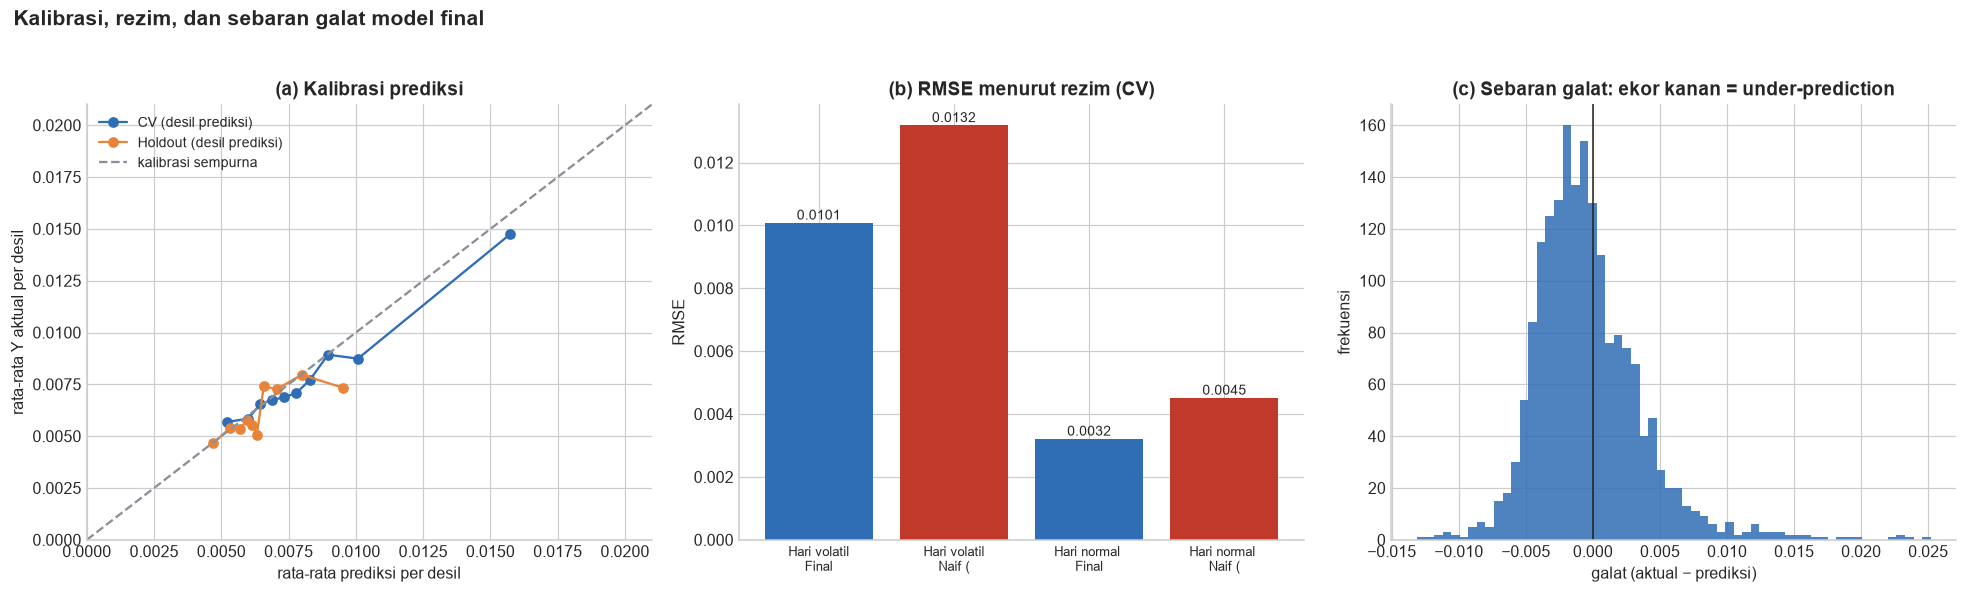

In [7]:
def mz(y_, p_):
    X = sm.add_constant(np.asarray(p_, float)); r = sm.OLS(np.asarray(y_, float), X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return r.params[0], r.params[1], r.bse[1], r.rsquared
rows = []
for scope, ix in [("CV 2016-2022", cv_idx), ("Holdout 2023-2024", ho_idx)]:
    for nm in ("Final: LightGBM", "HAR-OLS", "GJR-GARCH", "Naif (rv5)"):
        a0, b1, se_b, r2 = mz(yy.loc[ix], MODELS[nm].loc[ix])
        rows.append({"cakupan": scope, "model": nm, "intersep_a": a0, "kemiringan_b": b1, "se_b": se_b, "b=1 ditolak (|t|>1,96)": abs((b1 - 1) / se_b) > 1.96, "R2": r2})
mz_tbl = pd.DataFrame(rows).set_index(["cakupan", "model"])
display(mz_tbl.style.format({"intersep_a": "{:+.5f}", "kemiringan_b": "{:.3f}", "se_b": "{:.3f}", "R2": "{:.3f}"}))

hi = (yy > P90)
rows = []
for scope, ix in [("CV 2016-2022", cv_idx), ("Holdout 2023-2024", ho_idx)]:
    for reg, mask_ in [("Hari volatilitas tinggi (Y > P90)", hi.loc[ix]), ("Hari normal (Y <= P90)", ~hi.loc[ix])]:
        if mask_.sum() == 0: continue
        for nm in ("Final: LightGBM", "Naif (rv5)"):
            mm = metrics(yy.loc[ix][mask_], MODELS[nm].loc[ix][mask_])
            rows.append({"cakupan": scope, "rezim": reg, "n": int(mask_.sum()), "model": nm, "RMSE": mm["RMSE"], "MAE": mm["MAE"], "bias": float((MODELS[nm].loc[ix][mask_] - yy.loc[ix][mask_]).mean())})
reg_tbl = pd.DataFrame(rows).set_index(["cakupan", "rezim", "n", "model"])
display(reg_tbl.style.format({"RMSE": "{:.5f}", "MAE": "{:.5f}", "bias": "{:+.5f}"}))

e2 = ((yy.loc[cv_idx] - p_final.loc[cv_idx]) ** 2).sort_values(ascending=False)
share5 = e2.iloc[: int(0.05 * len(e2))].sum() / e2.sum() * 100
print(f"Konsentrasi galat (CV): 5% hari terburuk ({int(0.05*len(e2))} hari) menyumbang {share5:.1f}% dari jumlah kuadrat galat")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ax = axes[0]
for scope, ix, col in [("CV", cv_idx, BLUE), ("Holdout", ho_idx, ORANGE)]:
    d = pd.DataFrame({"p": p_final.loc[ix], "y": yy.loc[ix]}); d["bin"] = pd.qcut(d["p"], 10, duplicates="drop")
    g = d.groupby("bin").agg(p=("p", "mean"), y=("y", "mean"))
    ax.plot(g["p"], g["y"], "o-", color=col, label=f"{scope} (desil prediksi)")
lim = [0, 0.03]; ax.plot(lim, lim, "--", color=GREY, label="kalibrasi sempurna"); ax.set_xlim(0, 0.021); ax.set_ylim(0, 0.021)
ax.set_xlabel("rata-rata prediksi per desil"); ax.set_ylabel("rata-rata Y aktual per desil"); ax.set_title("(a) Kalibrasi prediksi"); ax.legend(fontsize=9)
ax = axes[1]
vals = [(reg_tbl.loc[(sc, rg, n_, md_), "RMSE"]) for (sc, rg, n_, md_) in reg_tbl.index if sc == "CV 2016-2022"]
lab = [f"{rg[:12]}\n{md_.split(':')[0][:6]}" for (sc, rg, n_, md_) in reg_tbl.index if sc == "CV 2016-2022"]
cols_ = [RED if "Naif" in l else BLUE for l in lab]
ax.bar(range(len(vals)), vals, color=cols_)
for i, v in enumerate(vals): ax.text(i, v + 0.0001, f"{v:.4f}", ha="center", fontsize=9)
ax.set_xticks(range(len(vals))); ax.set_xticklabels(lab, fontsize=8.5); ax.set_ylabel("RMSE"); ax.set_title("(b) RMSE menurut rezim (CV)")
ax = axes[2]
ax.hist((yy.loc[cv_idx] - p_final.loc[cv_idx]), bins=60, color=BLUE, alpha=0.85)
ax.axvline(0, color="#222", lw=1); ax.set_xlabel("galat (aktual − prediksi)"); ax.set_ylabel("frekuensi")
ax.set_title("(c) Sebaran galat: ekor kanan = under-prediction")
fig.suptitle("Kalibrasi, rezim, dan sebaran galat model final", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.03)
plt.tight_layout(); save_fig(fig, "e_2.png"); plt.show()

>INTERPRETASI

1. Kalibrasi pada CV hampir sempurna. Regresi Mincer-Zarnowitz memberi kemiringan $b=0{,}976$ (galat baku 0,111; hipotesis $b=1$ tidak ditolak), intersep -0,0002, dan $R^2=0{,}41$. Sebagai pembanding, kemiringan naif hanya 0,447 (terlalu dimuluskan), HAR 1,22 dan GJR 0,89.

2. Pada *holdout* tenang, prediksi terlalu ekstrem relatif terhadap variasi nyata. Kemiringan 0,663 (hipotesis $b=1$ ditolak) dan $R^2$ hanya 0,08. Artinya pada periode tenang model bereaksi lebih besar daripada yang terealisasi; variasi $Y$ pada periode itu kecil sehingga sinyal sulit dibedakan dari *noise*. Seluruh model, termasuk naif, memiliki kemiringan < 1 di sini.

3. Model memuluskan puncak (tabel rezim). Pada 125 hari volatilitas tinggi di CV, RMSE model 0,0101 (naif 0,0132, -23,6%) tetapi bias -0,0075: prediksi rata-rata jauh di bawah aktual. Bias ini sama arahnya dengan bias naif (-0,0069), jadi ini sifat umum masalahnya, bukan kelemahan khas model. Pada hari normal bias hanya +0,001 dan RMSE 0,0032 (naif 0,0045).

4. Galat sangat terkonsentrasi: 5% hari terburuk (91 hari) menyumbang 45,0% dari jumlah kuadrat galat CV. Karena itu analisis kesalahan (Bagian 7) memusatkan perhatian pada kejadian-kejadian tersebut.

5. Pada *holdout*, delapan hari bervolatilitas tinggi seluruhnya diprediksi di bawah aktual (bias -0,0097), mirip naif (-0,0102). Dengan hanya 8 peristiwa, kesimpulan statistik dari bagian ini lemah dan kami tidak menariknya lebih jauh.

### ****4. XAI Global: SHAP****

Metode. Kami memakai SHAP dengan algoritma *TreeExplainer*, yang menghitung nilai Shapley secara eksak untuk model pohon. Nilai Shapley berasal dari teori permainan kooperatif: kontribusi tiap fitur adalah rata-rata kontribusi marginalnya pada seluruh urutan penambahan fitur yang mungkin, sehingga jumlah kontribusi seluruh fitur ditambah nilai dasar tepat sama dengan prediksi (sifat *additivity*, kami verifikasi secara numerik).

Cara membaca. Model memprediksi $\ln(Y+0{,}001)$, sehingga nilai SHAP berada pada skala logaritma. Nilai SHAP $\varphi$ sebesar +0,20 berarti fitur itu menaikkan prediksi volatilitas sekitar $e^{0{,}20}-1\approx 22\%$ dibanding kondisi rata-rata. Interpretasi multiplikatif inilah yang menjadi alasan kami memilih target logaritma (Tahap 3), karena sesuai dengan cara manajer risiko berpikir ("volatilitas 1,5 kali lebih tinggi").

Rancangan. Penjelasan memakai rata-rata kelima *seed* model final. Penjelasan global dihitung pada seluruh data berlabel (3.820 baris). Penjelasan yang benar-benar *out-of-sample* untuk analisis kesalahan dihitung pada Bagian 5 dan 7.

SHAP menjelaskan apa yang dilakukan model, bukan mengapa pasar bergerak. "X3 menaikkan prediksi" tidak berarti "penurunan IHSG menyebabkan volatilitas"; melainkan bahwa model, yang dilatih pada pola historis, memakai X3 dengan cara itu.

Uji additivity SHAP: selisih maksimum |base + sum(SHAP) - prediksi| = 1.07e-14  (LULUS bila < 1e-6)


fitur,mean|SHAP| (ln),efek_relatif_tipikal_%,porsi_total_%
Vol. IHSG 66 hari (ln),0.0873,9.1,23.6
X1 Fear Gap,0.0615,6.3,16.6
Vol. IHSG 22 hari (ln),0.0549,5.6,14.9
X3 Drawdown-Vol,0.0546,5.6,14.8
Vol. IHSG 5 hari (ln),0.0478,4.9,12.9
Return IHSG 22 hari,0.0370,3.8,10.0
X2 Rupiah Shock,0.0264,2.7,7.1


Nilai dasar (prediksi rata-rata pada skala asli): 0.0071
Gambar disimpan: xLain-Lain/img/e_3.png


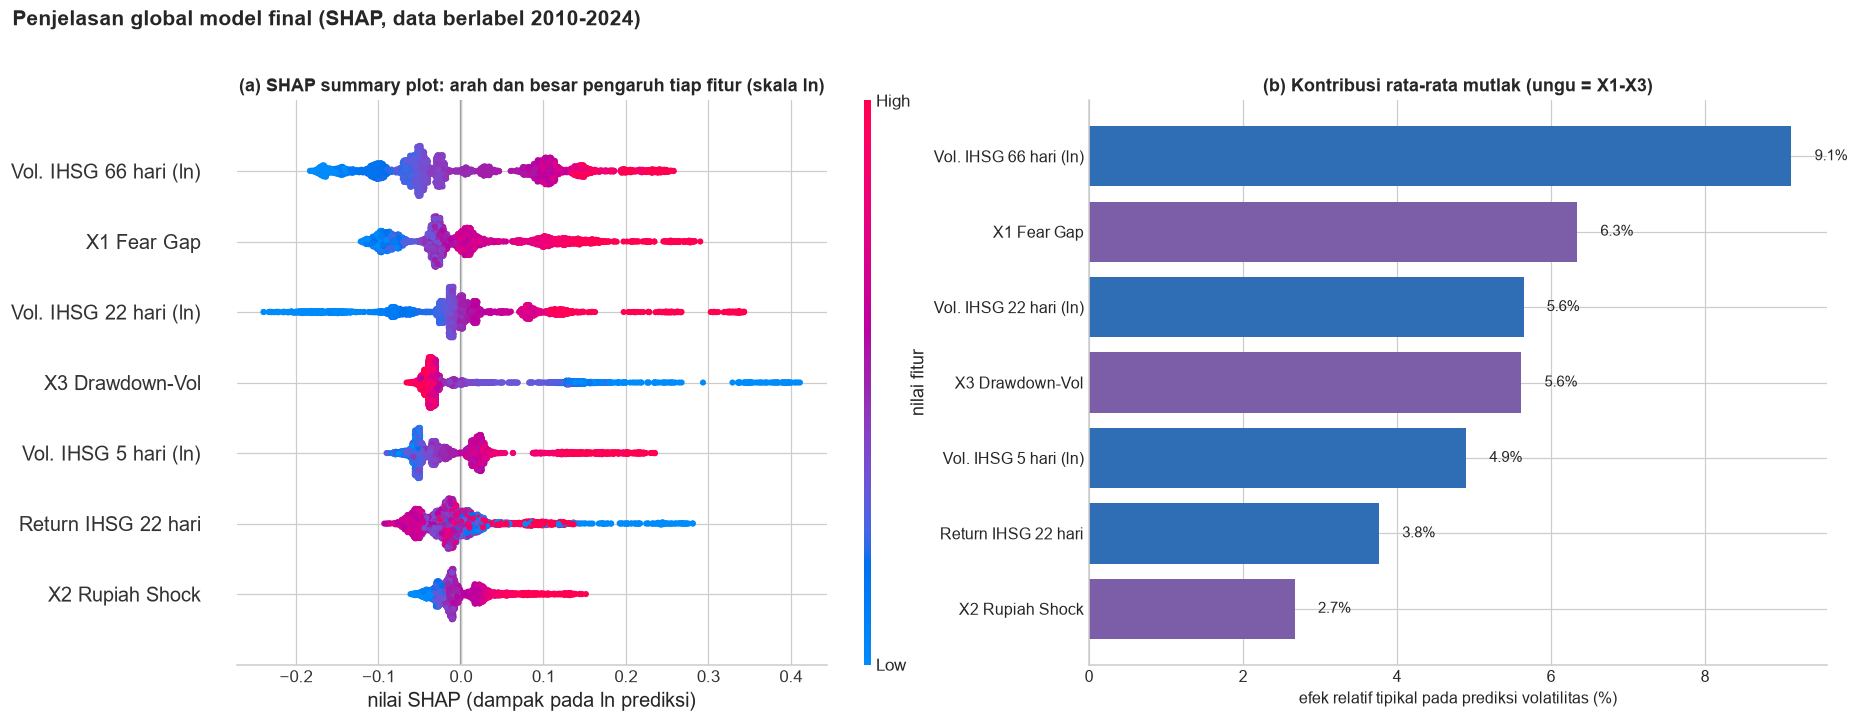

In [8]:
models = art["models"]
Xlab, Xte = F.loc[idx, FEATS], F.loc[test_idx, FEATS]
assert Xte.notna().all().all()

def shap_avg(X):
    svs, bases = [], []
    for m in models:
        ex = shap.TreeExplainer(m); svs.append(ex.shap_values(X)); bases.append(float(np.atleast_1d(ex.expected_value)[0]))
    return np.mean(svs, axis=0), float(np.mean(bases))
sv_lab, base_lab = shap_avg(Xlab)
sv_te, base_te = shap_avg(Xte)

# Uji additivity: nilai dasar + jumlah SHAP = prediksi model (rata-rata seed, skala log)
z_lab = np.mean([m.predict(Xlab) for m in models], axis=0)
err = np.abs(base_lab + sv_lab.sum(axis=1) - z_lab).max()
print(f"Uji additivity SHAP: selisih maksimum |base + sum(SHAP) - prediksi| = {err:.2e}  (LULUS bila < 1e-6)")
assert err < 1e-6

imp = pd.Series(np.abs(sv_lab).mean(axis=0), index=FEATS).sort_values(ascending=False)
imp_tbl = pd.DataFrame({"fitur": [FRIENDLY[c] for c in imp.index], "mean|SHAP| (ln)": imp.values, "efek_relatif_tipikal_%": (np.exp(imp.values) - 1) * 100,
                        "porsi_total_%": imp.values / imp.sum() * 100})
display(imp_tbl.style.hide(axis="index").format({"mean|SHAP| (ln)": "{:.4f}", "efek_relatif_tipikal_%": "{:.1f}", "porsi_total_%": "{:.1f}"}))
print(f"Nilai dasar (prediksi rata-rata pada skala asli): {np.exp(base_lab) - EPS_T:.4f}")

# summary plot + bar
fig = plt.figure(figsize=(17, 6.4))
ax1 = fig.add_subplot(1, 2, 1)
plt.sca(ax1)
shap.summary_plot(sv_lab, Xlab.rename(columns=FRIENDLY), plot_type="dot", show=False, max_display=7, color_bar_label="nilai fitur", plot_size=None)
ax1.set_title("(a) SHAP summary plot: arah dan besar pengaruh tiap fitur (skala ln)", fontsize=11.5, fontweight="bold"); ax1.set_xlabel("nilai SHAP (dampak pada ln prediksi)")
ax2 = fig.add_subplot(1, 2, 2)
ax2.barh([FRIENDLY[c] for c in imp.index][::-1], ((np.exp(imp.values) - 1) * 100)[::-1], color=[PURPLE if c in (X1, X2, X3) else BLUE for c in imp.index][::-1])
for i, v in enumerate(((np.exp(imp.values) - 1) * 100)[::-1]): ax2.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9.5)
ax2.set_xlabel("efek relatif tipikal pada prediksi volatilitas (%)"); ax2.set_title("(b) Kontribusi rata-rata mutlak (ungu = X1-X3)", fontsize=11.5, fontweight="bold")
fig.suptitle("Penjelasan global model final (SHAP, data berlabel 2010-2024)", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.02)
plt.tight_layout(); save_fig(fig, "e_3.png"); plt.show()

>INTERPRETASI

1. Verifikasi teknis lulus: nilai dasar + jumlah SHAP sama dengan prediksi model dengan selisih maksimum $1\times10^{-14}$ (sifat *additivity* terpenuhi). Nilai dasar adalah prediksi untuk kondisi rata-rata, yaitu 0,0071.

2. Peringkat kontribusi (rata-rata |SHAP|; porsi dari total): volatilitas IHSG 66 hari 23,6%, X1 *Fear Gap* 16,6%, volatilitas 22 hari 14,9%, X3 *Drawdown-Vol* 14,8%, volatilitas 5 hari 12,9%, *return* 22 hari 10,0%, dan X2 *Rupiah Shock* 7,1%. Satu fitur rata-rata menggeser prediksi sekitar 3% sampai 9%.

3. Dua keluarga fitur berbagi kerja hampir seimbang. Struktur HAR (tiga volatilitas) menyumbang 51,4%, sedangkan X1-X3 menyumbang 38,5%, dan sisanya (10,0%) dari momentum. Ini menjawab pertanyaan studi kasus *"fitur mana yang memiliki bobot paling besar dalam menentukan prediksi"*: volatilitas masa lalu IHSG tetap penting, namun fitur ekonomi yang kami rancang membawa hampir 40% penjelasan, dengan X1 menjadi fitur terpenting kedua secara keseluruhan.

4. Arah pengaruh sesuai teori (Gambar a). Nilai volatilitas tinggi (merah) mendorong prediksi naik. X3: nilai rendah (biru, yaitu penurunan dalam dari puncak) mendorong SHAP positif hingga sekitar +0,4 (sekitar +50% pada prediksi), sedangkan nilai tinggi (IHSG dekat puncak) sedikit menurunkan prediksi. X1 dan X2: nilai tinggi (merah) mendorong SHAP positif. *Return* 22 hari: *return* negatif (biru) menaikkan prediksi, konsisten dengan *leverage effect*.

5. Dalam bahasa bisnis: model menaikkan prediksi risiko ketika (a) pasar sudah bergejolak, (b) IHSG jatuh dalam dari puncaknya, (c) ketakutan global melebihi gejolak lokal yang sudah terjadi, dan (d) rupiah melemah tajam. Tidak ada satu pun fitur yang bekerja berlawanan dengan logika ini.

Gambar disimpan: xLain-Lain/img/e_4.png


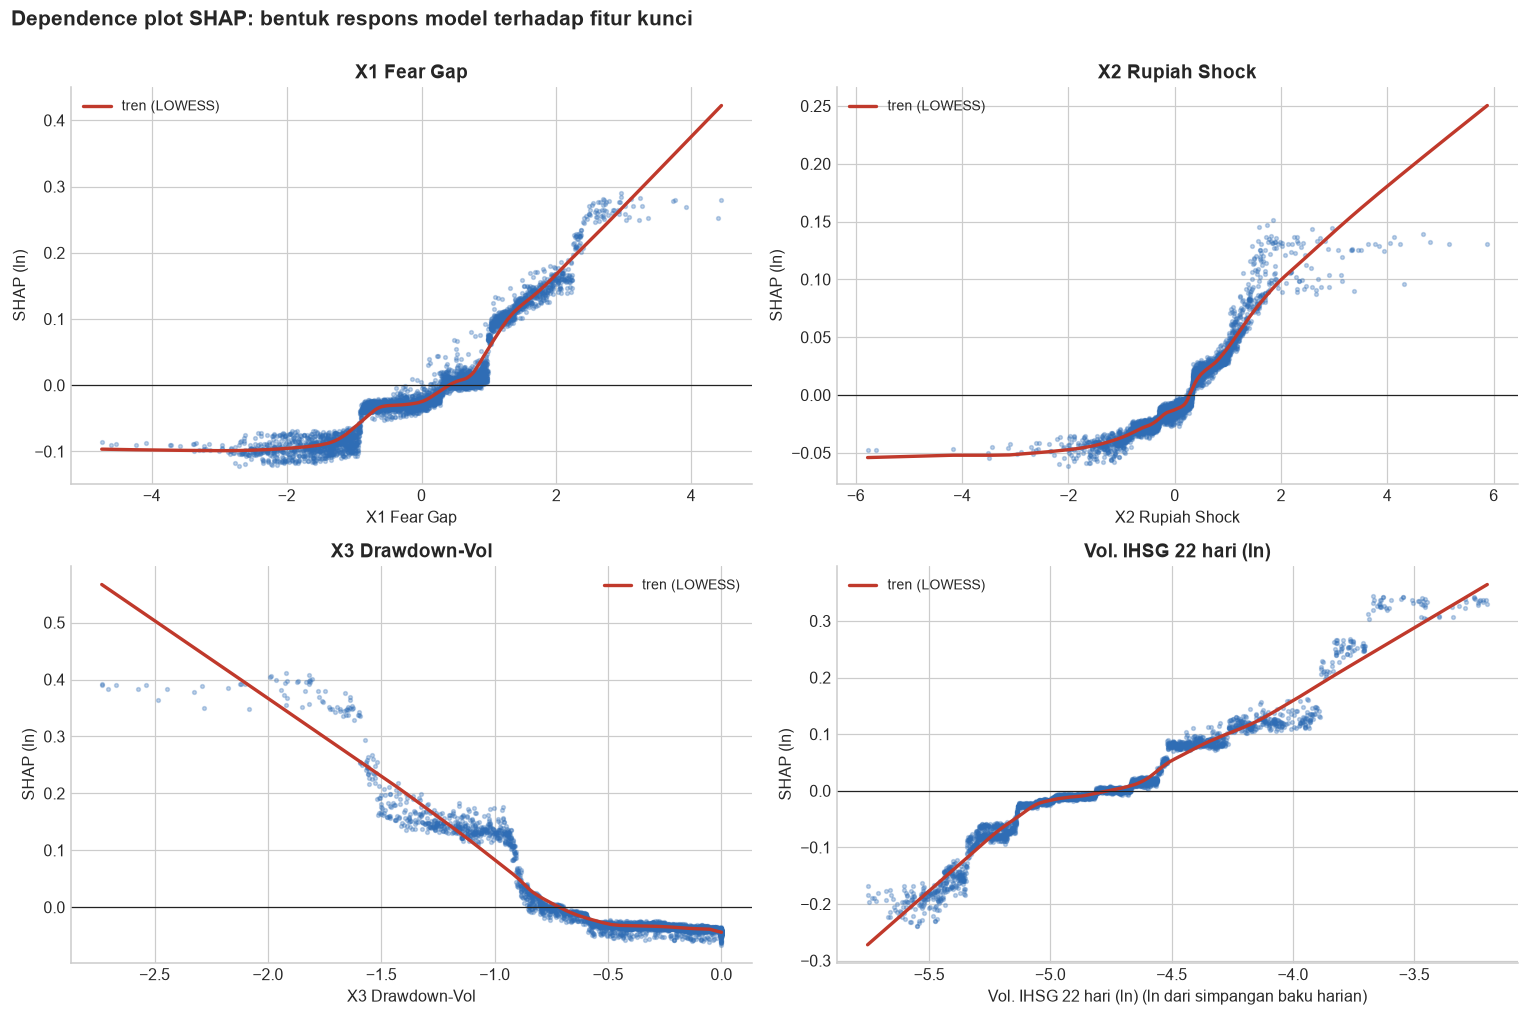

,arah_teori,SHAP_pada_P5,SHAP_pada_P95,rentang_ln,selisih_efek_%,monoton_sesuai_teori
fitur,,,,,,
X1 Fear Gap,+,-0.096,+0.158,+0.254,+28.9,True
X2 Rupiah Shock,+,-0.040,+0.065,+0.105,+11.1,True
X3 Drawdown-Vol,-,+0.174,-0.044,-0.218,-19.6,True
Vol. IHSG 22 hari (ln),+,-0.143,+0.147,+0.290,+33.6,True


In [9]:
from statsmodels.nonparametric.smoothers_lowess import lowess
show_feats = [X1, X2, X3, "log_rv22"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9.2))
dep_rows = []
for ax, c in zip(axes.ravel(), show_feats):
    j = FEATS.index(c); xv, sv = Xlab[c].to_numpy(), sv_lab[:, j]
    ax.scatter(xv, sv, s=6, alpha=0.30, color=BLUE)
    lw = lowess(sv, xv, frac=0.25, return_sorted=True); ax.plot(lw[:, 0], lw[:, 1], color=RED, lw=2.2, label="tren (LOWESS)")
    ax.axhline(0, color="#222", lw=0.8)
    ax.set_xlabel(FRIENDLY[c] + (" (ln dari simpangan baku harian)" if c.startswith("log_") else "")); ax.set_ylabel("SHAP (ln)"); ax.set_title(FRIENDLY[c]); ax.legend(fontsize=9, loc="best")
    q = np.quantile(xv, [0.05, 0.95]); lo, hi_ = np.interp(q, lw[:, 0], lw[:, 1])
    dep_rows.append({"fitur": FRIENDLY[c], "arah_teori": {X1: "+", X2: "+", X3: "-", "log_rv22": "+"}[c], "SHAP_pada_P5": lo, "SHAP_pada_P95": hi_, "rentang_ln": hi_ - lo,
                     "selisih_efek_%": (np.exp(hi_ - lo) - 1) * 100, "monoton_sesuai_teori": bool((hi_ - lo) * {X1: 1, X2: 1, X3: -1, "log_rv22": 1}[c] >= -1e-9)})
fig.suptitle("Dependence plot SHAP: bentuk respons model terhadap fitur kunci", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.0)
plt.tight_layout(); save_fig(fig, "e_4.png"); plt.show()
dep_tbl = pd.DataFrame(dep_rows).set_index("fitur")
display(dep_tbl.style.format({"SHAP_pada_P5": "{:+.3f}", "SHAP_pada_P95": "{:+.3f}", "rentang_ln": "{:+.3f}", "selisih_efek_%": "{:+.1f}"}))

>INTERPRETASI

1. Seluruh fitur kunci merespons ke arah teori ekonomi. Dari persentil ke-5 ke persentil ke-95 fitur: X1 menaikkan prediksi sekitar +28,9%, X2 +11,1%, volatilitas 22 hari +33,6%, dan X3 menurunkan prediksi sekitar 19,6% (artinya penurunan IHSG yang terdalam menambah sekitar 19% dibanding kondisi dekat puncak). Hal ini wajib terjadi karena kendala monoton, tetapi bentuk kurvanya tidak dipaksakan dan menunjukkan efek berundak (garis LOWESS pada Gambar), yang sejalan dengan temuan profil kuintil di Tahap 3.

2. Fitur yang paling kecil dampaknya adalah X2: rentangnya hanya +11,1%, konsisten dengan kontribusi marginalnya yang kecil pada Notebook 3. Kami menyatakannya apa adanya.

3. Urutan pengaruh pada rentang realistis (P5→P95): volatilitas 22 hari (≈34%) > X1 (≈29%) > X3 (≈20%) > X2 (≈11%). Dengan demikian, selain peringkat rata-rata, tersedia ukuran kedua: seberapa besar prediksi bergeser antara kondisi biasa dan kondisi ekstrem.

### ****5. Kestabilan Penjelasan****

Penjelasan yang hanya tampak meyakinkan pada satu sampel berbahaya, karena dapat memberi rasa aman palsu kepada komite risiko. Kami menguji kestabilannya dengan dua cara yang saling bebas:

1. Antar fold. Pada setiap fold (7 fold CV + *holdout*), kami melatih model hanya pada data latih fold itu, menghitung SHAP pada data validasinya (benar-benar *out-of-sample*), lalu membandingkan peringkat kontribusi antar fold dan terhadap penjelasan global. Hasil ini juga dipakai kembali pada analisis kesalahan (Bagian 7).

2. Metode berbeda. *Permutation importance* mengukur berapa besar RMSE naik bila satu fitur diacak pada data validasi. Metode ini tidak bergantung pada SHAP; bila keduanya menghasilkan peringkat serupa, kesimpulannya lebih kokoh.

Fitur terpenting per fold: {'CV2016': 'X1 Fear Gap', 'CV2017': 'Vol. IHSG 66 hari (ln)', 'CV2018': 'X1 Fear Gap', 'CV2019': 'Vol. IHSG 66 hari (ln)', 'CV2020': 'Vol. IHSG 66 hari (ln)', 'CV2021': 'X1 Fear Gap', 'CV2022': 'X1 Fear Gap', 'Holdout 2023-2024': 'Vol. IHSG 66 hari (ln)'}
Korelasi peringkat (Spearman) antar fold: rata-rata 0.62, minimum 0.18 | terhadap penjelasan global: rata-rata 0.77, minimum 0.57


,SHAP mean|.| (holdout),Permutation: kenaikan RMSE,peringkat SHAP,peringkat permutation
Vol. IHSG 66 hari (ln),0.0816,-0.00002,1,6
Vol. IHSG 22 hari (ln),0.0691,0.00006,2,3
X3 Drawdown-Vol,0.0587,0.00010,3,2
X1 Fear Gap,0.0566,0.00013,4,1
Vol. IHSG 5 hari (ln),0.0407,-0.00000,5,4
Return IHSG 22 hari,0.0283,-0.00004,6,7
X2 Rupiah Shock,0.0270,-0.00000,7,5


Korelasi peringkat SHAP vs permutation importance (holdout): 0.25


,CV2016,CV2017,CV2018,CV2019,CV2020,CV2021,CV2022,Holdout 2023-2024
Struktur HAR (vol 5/22/66 hari),45%,62%,38%,47%,51%,40%,43%,53%
X1-X3 (fitur baru),44%,29%,54%,44%,37%,47%,47%,39%
Momentum (return 22 hari),11%,9%,8%,10%,12%,13%,10%,8%


Porsi X1-X3 antar fold: min 29%, maks 54%, rata-rata 43% | Porsi struktur HAR: min 38%, maks 62%
Gambar disimpan: xLain-Lain/img/e_5.png


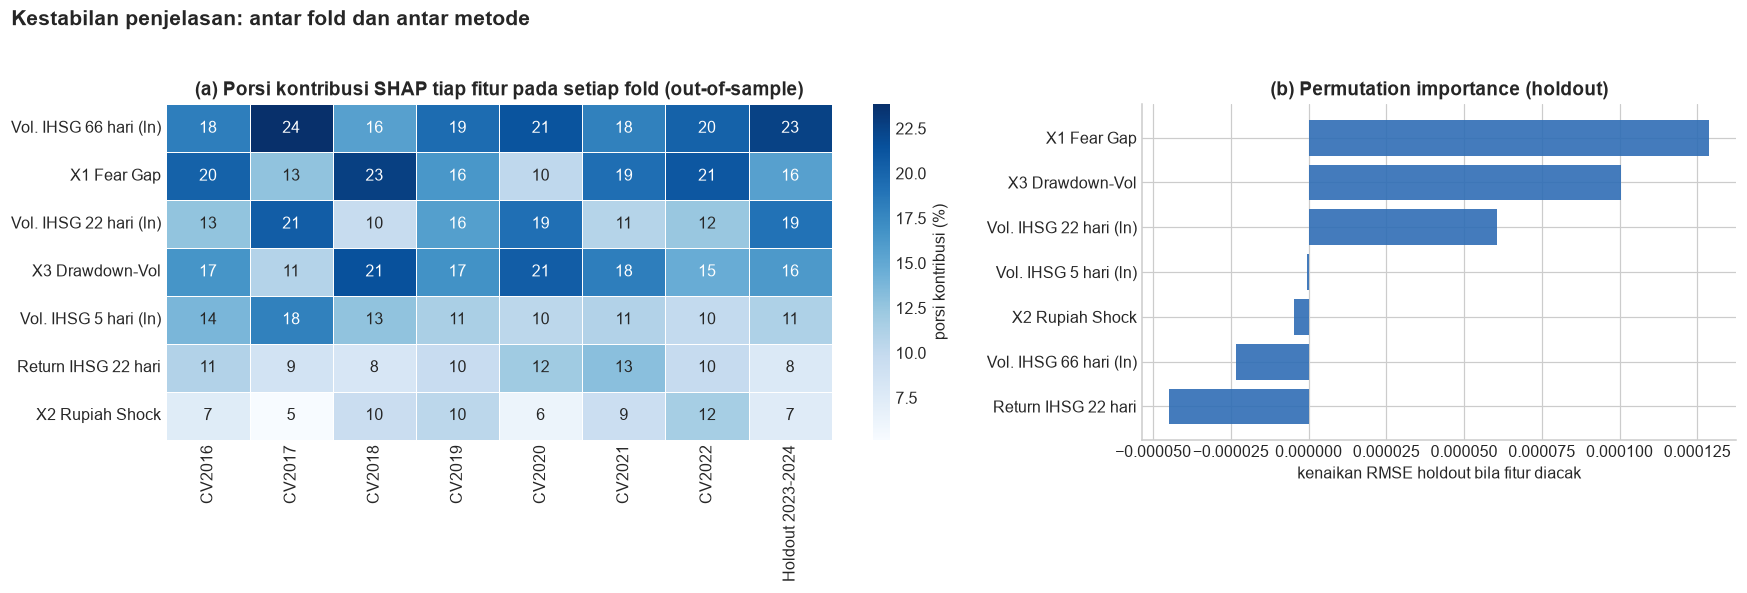

In [10]:
fold_imp, sv_oos, fold_models = {}, {}, {}
for f in all_folds:
    m, sm_ = fit_model(F.loc[f["train"], FEATS], y.loc[f["train"]], seed=1)
    ex = shap.TreeExplainer(m); sv = ex.shap_values(F.loc[f["val"], FEATS])
    fold_imp[f["name"]] = pd.Series(np.abs(sv).mean(axis=0), index=FEATS)
    sv_oos[f["name"]] = pd.DataFrame(sv, index=f["val"], columns=FEATS); fold_models[f["name"]] = (m, sm_, float(np.atleast_1d(ex.expected_value)[0]))
FI = pd.DataFrame(fold_imp)
share = FI / FI.sum() * 100
glob = imp.reindex(FEATS)
rk = pd.DataFrame({c: stats.spearmanr(FI[c], glob)[0] for c in FI.columns}, index=["Spearman thd global"]).T
pairs = [stats.spearmanr(FI[a], FI[b])[0] for i, a in enumerate(FI.columns) for b in FI.columns[i + 1:]]
top1 = FI.idxmax().map(FRIENDLY)
print("Fitur terpenting per fold:", top1.to_dict())
print(f"Korelasi peringkat (Spearman) antar fold: rata-rata {np.mean(pairs):.2f}, minimum {np.min(pairs):.2f} | terhadap penjelasan global: rata-rata {rk.iloc[:,0].mean():.2f}, minimum {rk.iloc[:,0].min():.2f}")

# Permutation importance pada holdout (model dilatih pada data latih holdout)
m_h, sm_h, _ = fold_models[holdout["name"]]
Xh, yh = F.loc[ho_idx, FEATS], y.loc[ho_idx]
base_rmse = np.sqrt(np.mean((yh - predict_y(m_h, sm_h, Xh)) ** 2))
rng = np.random.default_rng(SEED); perm = {}
for c in FEATS:
    inc = []
    for _ in range(50):
        Xp = Xh.copy(); Xp[c] = rng.permutation(Xp[c].to_numpy())
        inc.append(np.sqrt(np.mean((yh - predict_y(m_h, sm_h, Xp)) ** 2)) - base_rmse)
    perm[c] = np.mean(inc)
perm = pd.Series(perm)
shap_h = FI[holdout["name"]]
cmp_tbl = pd.DataFrame({"SHAP mean|.| (holdout)": shap_h, "Permutation: kenaikan RMSE": perm, "peringkat SHAP": shap_h.rank(ascending=False).astype(int), "peringkat permutation": perm.rank(ascending=False).astype(int)})
cmp_tbl.index = [FRIENDLY[c] for c in cmp_tbl.index]
display(cmp_tbl.sort_values("peringkat SHAP").style.format({"SHAP mean|.| (holdout)": "{:.4f}", "Permutation: kenaikan RMSE": "{:.5f}"}))
rho_sp = stats.spearmanr(shap_h, perm)[0]
print(f"Korelasi peringkat SHAP vs permutation importance (holdout): {rho_sp:.2f}")

# Kestabilan pada tingkat GRUP fitur (fitur HAR saling berkorelasi tinggi sehingga SHAP membagi kredit di antaranya secara tidak stabil)
GROUPS = {"Struktur HAR (vol 5/22/66 hari)": ["log_rv5", "log_rv22", "log_rv66"], "X1-X3 (fitur baru)": [X1, X2, X3], "Momentum (return 22 hari)": ["ihsg_ret22"]}
grp = pd.DataFrame({g: FI.loc[cols].sum() for g, cols in GROUPS.items()}).T
grp_share = grp / grp.sum() * 100
display(grp_share.style.format("{:.0f}%").set_caption("Porsi kontribusi SHAP per grup fitur pada setiap fold (out-of-sample)"))
print("Porsi X1-X3 antar fold: min {:.0f}%, maks {:.0f}%, rata-rata {:.0f}% | Porsi struktur HAR: min {:.0f}%, maks {:.0f}%".format(
      grp_share.loc["X1-X3 (fitur baru)"].min(), grp_share.loc["X1-X3 (fitur baru)"].max(), grp_share.loc["X1-X3 (fitur baru)"].mean(),
      grp_share.loc["Struktur HAR (vol 5/22/66 hari)"].min(), grp_share.loc["Struktur HAR (vol 5/22/66 hari)"].max()))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(share.rename(index=FRIENDLY).loc[[FRIENDLY[c] for c in glob.sort_values(ascending=False).index]], annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, ax=axes[0], cbar_kws={"label": "porsi kontribusi (%)"})
axes[0].set_title("(a) Porsi kontribusi SHAP tiap fitur pada setiap fold (out-of-sample)"); axes[0].grid(False)
ax = axes[1]; o = cmp_tbl.sort_values("Permutation: kenaikan RMSE")
ax.barh(o.index, o["Permutation: kenaikan RMSE"], color=BLUE, alpha=0.9); ax.set_xlabel("kenaikan RMSE holdout bila fitur diacak"); ax.set_title("(b) Permutation importance (holdout)")
fig.suptitle("Kestabilan penjelasan: antar fold dan antar metode", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.03)
plt.tight_layout(); save_fig(fig, "e_5.png"); plt.show()

>INTERPRETASI (Bagian ini sengaja dibuat untuk mengungkap kelemahan penjelasan, bukan menyembunyikannya.)

1. Peringkat fitur individual tidak sepenuhnya stabil. Korelasi peringkat SHAP antar fold rata-rata 0,62 (minimum 0,18), dan terhadap penjelasan global rata-rata 0,77 (minimum 0,57). Fitur terpenting pada tiap fold bergantian antara X1 *Fear Gap* (2016, 2018, 2021, 2022) dan volatilitas 66 hari (2017, 2019, 2020).

2. Penyebabnya dapat dijelaskan, dan terkait struktur data. Ketiga fitur volatilitas IHSG saling berkorelasi tinggi (0,47 sampai 0,81) sehingga saling menggantikan; SHAP membagi kredit di antara fitur yang berkorelasi secara tidak stabil, dan *permutation importance* untuk volatilitas 66 hari dan 5 hari praktis nol (−0,00002 dan 0,00000) karena fitur lain mengambil alih bila salah satunya diacak. Korelasi peringkat antara SHAP dan *permutation importance* pada *holdout* hanya 0,25.

3. Yang stabil adalah tingkat grup dan fitur baru. Porsi X1-X3 berkisar 29% sampai 54% (rata-rata 43%) pada seluruh fold, struktur HAR 38% sampai 62%, dan momentum 8% sampai 13%. Pada kedua metode, X1 dan X3 berada di empat besar pada *holdout* (permutation: X1 peringkat 1, X3 peringkat 2, volatilitas 22 hari peringkat 3; SHAP: X3 peringkat 3, X1 peringkat 4 pada *holdout*). Arah pengaruh semuanya konsisten antar fold dan metode.

4. Kesimpulan yang dapat dipertahankan di depan juri: kami tidak mengklaim peringkat tepat antar fitur volatilitas yang saling menggantikan. Kami mengklaim dua hal yang terbukti stabil: (i) arah dan bentuk pengaruh fitur ekonomi sesuai teori, dan (ii) fitur ekonomi baru menyumbang bagian yang substansial dan konsisten dari penjelasan model (sekitar 40%).

### ****6. XAI Lokal: Tanggal Berisiko Tinggi pada Data Uji****

Studi kasus meminta kami memilih tanggal ketika model memprediksi volatilitas sangat tinggi, menampilkan penjelasan lokalnya (*waterfall*), dan menerjemahkannya ke bahasa bisnis. Kami memilih puncak prediksi pada tiap episode di data uji (dipisah minimal 30 hari), sehingga yang dibedah adalah momen-momen yang paling relevan bagi manajemen risiko.

Cara membaca *waterfall*. Mulai dari nilai dasar (prediksi untuk kondisi rata-rata), setiap batang menambah atau mengurangi $\ln$ prediksi. Batang merah menaikkan prediksi volatilitas, batang biru menurunkannya. Di sisi kanan setiap batang ditulis efek relatifnya dalam persen (mis. +35% berarti fitur itu menaikkan prediksi sekitar 35% dibanding kondisi rata-rata).

Catatan penting. Pada data uji kami tidak memiliki $Y$ aktual, sehingga penjelasan ini menerangkan *mengapa model memprediksi tinggi*, bukan *apakah prediksinya benar*. Kebenaran prediksi hanya dapat dinilai pada CV dan *holdout* (Bagian 2 dan 7).

Tanggal yang dibedah (puncak prediksi tiap episode): [('2025-04-08', 0.0303), ('2026-03-27', 0.0279), ('2026-05-21', 0.0285)]
Gambar disimpan: xLain-Lain/img/e_6.png


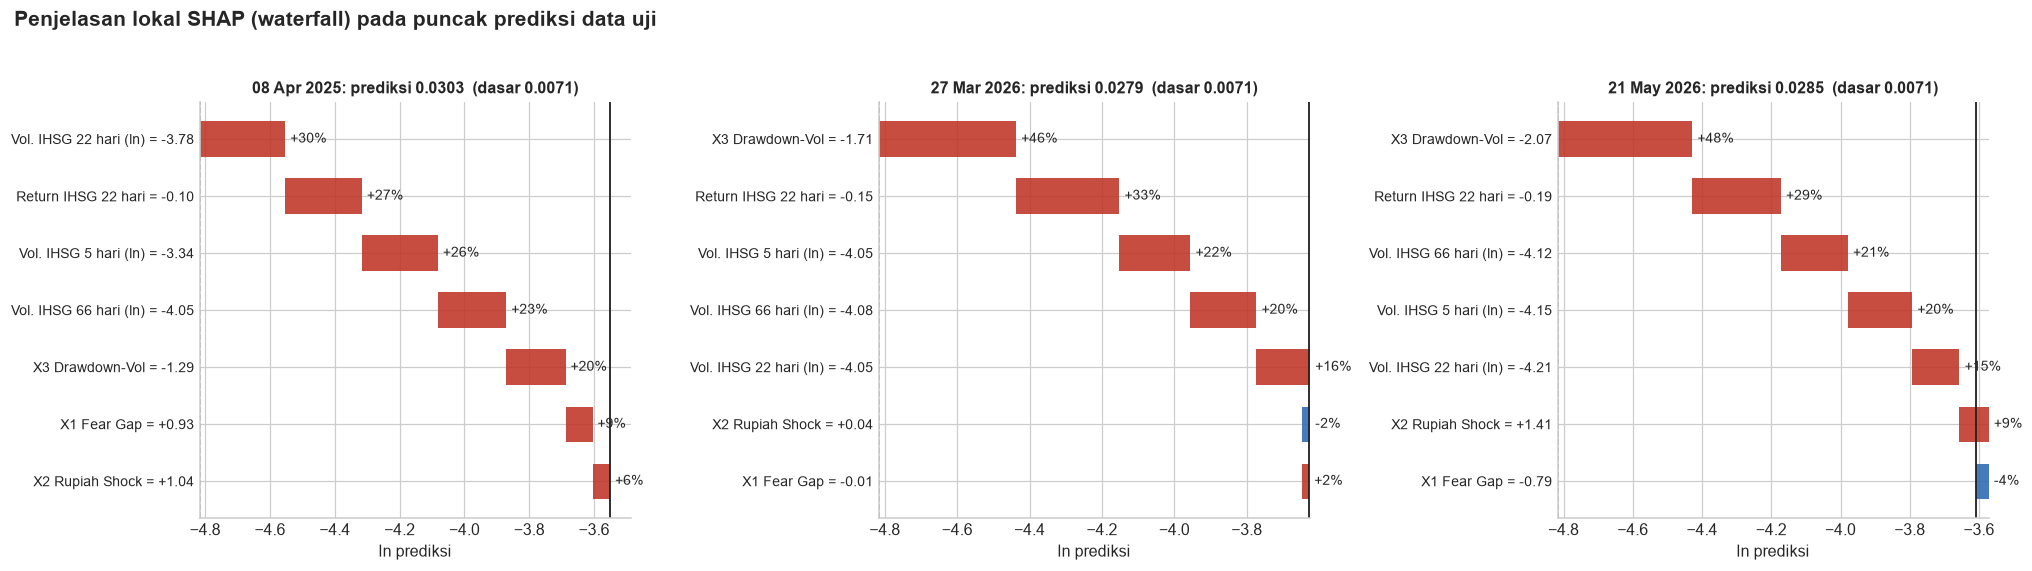


=== 08 April 2025 | prediksi volatilitas 5 hari ke depan = 0.0303 (3.7 kali rata-rata Y data latih) ===


fitur,nilai,SHAP_ln,efek_relatif_%,arti_bisnis
Vol. IHSG 22 hari (ln),-3.78,+0.265,+30,volatilitas harian IHSG (22 hari) = 2.26%
Return IHSG 22 hari,-0.10,+0.236,+27,IHSG turun 9.6% dalam 22 hari
Vol. IHSG 5 hari (ln),-3.34,+0.234,+26,volatilitas harian IHSG (5 hari) = 3.53%
Vol. IHSG 66 hari (ln),-4.05,+0.211,+23,volatilitas harian IHSG (66 hari) = 1.73%
X3 Drawdown-Vol,-1.29,+0.183,+20,IHSG berada 1.3 simpangan baku volatilitas di bawah puncak 60 harinya
X1 Fear Gap,+0.93,+0.083,+9,ketakutan global (VIX) 0.9 simpangan baku di atas gejolak lokal yang sudah terjadi
X2 Rupiah Shock,+1.04,+0.054,+6,rupiah melemah 1.0 simpangan baku dalam 5 hari



=== 27 March 2026 | prediksi volatilitas 5 hari ke depan = 0.0279 (3.4 kali rata-rata Y data latih) ===


fitur,nilai,SHAP_ln,efek_relatif_%,arti_bisnis
X3 Drawdown-Vol,-1.71,+0.379,+46,IHSG berada 1.7 simpangan baku volatilitas di bawah puncak 60 harinya
Return IHSG 22 hari,-0.15,+0.285,+33,IHSG turun 14.7% dalam 22 hari
Vol. IHSG 5 hari (ln),-4.05,+0.196,+22,volatilitas harian IHSG (5 hari) = 1.73%
Vol. IHSG 66 hari (ln),-4.08,+0.182,+20,volatilitas harian IHSG (66 hari) = 1.68%
Vol. IHSG 22 hari (ln),-4.05,+0.148,+16,volatilitas harian IHSG (22 hari) = 1.74%
X2 Rupiah Shock,+0.04,-0.021,-2,rupiah melemah 0.0 simpangan baku dalam 5 hari
X1 Fear Gap,-0.01,+0.018,+2,gejolak lokal 0.0 simpangan baku di atas ketakutan global (VIX)



=== 21 May 2026 | prediksi volatilitas 5 hari ke depan = 0.0285 (3.4 kali rata-rata Y data latih) ===


fitur,nilai,SHAP_ln,efek_relatif_%,arti_bisnis
X3 Drawdown-Vol,-2.07,+0.389,+48,IHSG berada 2.1 simpangan baku volatilitas di bawah puncak 60 harinya
Return IHSG 22 hari,-0.19,+0.256,+29,IHSG turun 19.4% dalam 22 hari
Vol. IHSG 66 hari (ln),-4.12,+0.193,+21,volatilitas harian IHSG (66 hari) = 1.62%
Vol. IHSG 5 hari (ln),-4.15,+0.186,+20,volatilitas harian IHSG (5 hari) = 1.57%
Vol. IHSG 22 hari (ln),-4.21,+0.137,+15,volatilitas harian IHSG (22 hari) = 1.47%
X2 Rupiah Shock,+1.41,+0.085,+9,rupiah melemah 1.4 simpangan baku dalam 5 hari
X1 Fear Gap,-0.79,-0.037,-4,gejolak lokal 0.8 simpangan baku di atas ketakutan global (VIX)


In [11]:
pt = pd.read_csv(CLEAN_DIR / "predictions_test.csv", parse_dates=["Date"]).set_index("Date")["Prediksi_Y"]
assert len(pt) == len(test_idx)

def pick_peaks(s, k=3, sep=30):
    out, taken = [], []
    for d, v in s.sort_values(ascending=False).items():
        if all(abs((d - t).days) > sep for t in taken): out.append(d); taken.append(d)
        if len(out) == k: break
    return sorted(out)
dates = pick_peaks(pt, k=3, sep=30)
print("Tanggal yang dibedah (puncak prediksi tiap episode):", [(d.strftime("%Y-%m-%d"), round(float(pt[d]), 4)) for d in dates])

def translate(c, v):
    if c == X3:  return f"IHSG berada {abs(v):.1f} simpangan baku volatilitas di bawah puncak 60 harinya" if v < -0.05 else "IHSG dekat puncak 60 harinya"
    if c == X2:  return f"rupiah {'melemah' if v > 0 else 'menguat'} {abs(v):.1f} simpangan baku dalam 5 hari"
    if c == X1:  return ("ketakutan global (VIX) {0:.1f} simpangan baku di atas gejolak lokal yang sudah terjadi" if v > 0 else "gejolak lokal {0:.1f} simpangan baku di atas ketakutan global (VIX)").format(abs(v))
    if c == "ihsg_ret22": return f"IHSG {'naik' if v > 0 else 'turun'} {abs(v)*100:.1f}% dalam 22 hari"
    return f"volatilitas harian IHSG ({c.split('_')[1].replace('rv','')} hari) = {(np.exp(v) - EPS_LOG)*100:.2f}%"

def waterfall_ax(ax, base, phi, xrow, title):
    order = np.argsort(-np.abs(phi)); cum = base; ypos = list(range(len(order)))[::-1]
    for yp, j in zip(ypos, order):
        ax.barh(yp, phi[j], left=cum, color=(RED if phi[j] > 0 else BLUE), alpha=0.9, height=0.62)
        ax.text(max(cum, cum + phi[j]) + 0.015, yp, f"{(np.exp(phi[j]) - 1) * 100:+.0f}%", va="center", fontsize=9)
        cum += phi[j]
    ax.axvline(base, color=GREY, ls="--", lw=1); ax.axvline(cum, color="#222", lw=1.2)
    ax.set_yticks(ypos); ax.set_yticklabels([f"{FN[j]} = {xrow.iloc[j]:+.2f}" for j in order], fontsize=9)
    ax.set_xlabel("ln prediksi"); ax.set_title(title, fontsize=10.5)
    return cum

fig, axes = plt.subplots(1, len(dates), figsize=(6.2 * len(dates), 5.0))
loc_tables = {}
for ax, d in zip(np.atleast_1d(axes), dates):
    i = test_idx.get_loc(d); phi = sv_te[i]; xrow = Xte.iloc[i]
    zf = waterfall_ax(ax, base_te, phi, xrow, f"{d:%d %b %Y}: prediksi {pt[d]:.4f}  (dasar {np.exp(base_te)-EPS_T:.4f})")
    rows = [{"fitur": FRIENDLY[c], "nilai": xrow[c], "SHAP_ln": phi[j], "efek_relatif_%": (np.exp(phi[j]) - 1) * 100, "arti_bisnis": translate(c, xrow[c])} for j, c in enumerate(FEATS)]
    loc_tables[d] = pd.DataFrame(rows).sort_values("SHAP_ln", key=np.abs, ascending=False)
fig.suptitle("Penjelasan lokal SHAP (waterfall) pada puncak prediksi data uji", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.03)
plt.tight_layout(); save_fig(fig, "e_6.png"); plt.show()

for d, t in loc_tables.items():
    print(f"\n=== {d:%d %B %Y} | prediksi volatilitas 5 hari ke depan = {pt[d]:.4f} ({pt[d]/yy.mean():.1f} kali rata-rata Y data latih) ===")
    display(t.style.hide(axis="index").format({"nilai": "{:+.2f}", "SHAP_ln": "{:+.3f}", "efek_relatif_%": "{:+.0f}"}).set_properties(**{"text-align": "left"}))

>INTERPRETASI (tiga tanggal berisiko tinggi pada data uji). (Rata-rata $Y$ data latih = 0,0083; dasar model = 0,0071.)

① 8 April 2025: prediksi 0,0303 (3,7 kali rata-rata), pasar yang *sedang* bergejolak. Hampir seluruh dorongan berasal dari gejolak yang sudah terjadi: volatilitas 22 hari 2,26% per hari (+30%), IHSG turun 9,6% dalam 22 hari (+27%), volatilitas 5 hari 3,53% per hari (+26%), volatilitas 66 hari (+23%), dan kedalaman penurunan 1,3 simpangan baku dari puncak (+20%). Saluran global ikut menambah tetapi lebih kecil: ketakutan global 0,9 simpangan baku di atas gejolak lokal (X1, +9%) dan rupiah melemah 1,0 simpangan baku dalam 5 hari (X2, +6%). *Bacaan bisnis*: model membaca "krisis yang sedang berlangsung dan kemungkinan berlanjut lima hari ke depan"; sebagian besar sinyalnya adalah turbulensi domestik yang sudah tampak, diperkuat tekanan eksternal.

② 27 Maret 2026: prediksi 0,0279 (3,4 kali), tekanan yang bersumber di dalam negeri. Kontribusi terbesar adalah X3: IHSG 1,7 simpangan baku di bawah puncak 60 harinya (+46%), disusul IHSG turun 14,7% dalam 22 hari (+33%). Volatilitas harian hanya sekitar 1,7% (kontribusi +16% sampai +22%). Saluran global netral: X1 ≈ 0 (+2%) dan X2 −2%. *Bacaan bisnis*: penurunan pasar domestik yang dalam dan berkepanjangan, tanpa ketakutan global (VIX) maupun tekanan kurs. Inilah pola yang ditunjukkan nilai X1 sangat negatif pada Tahap 3.

③ 21 Mei 2026: prediksi 0,0285 (3,4 kali), penurunan paling dalam dalam sampel uji. X3: IHSG 2,1 simpangan baku di bawah puncak 60 hari (+48%), IHSG turun 19,4% dalam 22 hari (+29%), rupiah melemah 1,4 simpangan baku (X2, +9%), sedangkan X1 sedikit menurunkan prediksi (-4%, gejolak lokal melampaui ketakutan global).

Nilai tambah fitur baru terlihat pada perbandingan ① dan ③. Prediksi kedua tanggal hampir sama (0,0303 vs 0,0285), padahal volatilitas 5 hari tanggal ③ (1,57% per hari) kurang dari separuh tanggal ① (3,53%). Hal ini terjadi karena pada tanggal ③ X3 dan *return* 22 hari (penurunan dalam yang sudah berlangsung) memberi sinyal peringatan sebelum gejolak harian meledak. Model berbasis HAR murni tidak memiliki sinyal seperti itu.

ini penjelasan atas apa yang dipakai model, bukan penyebab pergerakan pasar, dan $Y$ aktual pada tanggal-tanggal ini tidak tersedia.

### ****7. Analisis Kesalahan Berbasis XAI****

Studi kasus meminta: *"Alih-alih sekadar menduga, gunakan XAI untuk membedah kesalahan."* Kami melakukannya secara sistematis pada seluruh prediksi *out-of-sample* (CV dan *holdout*), dengan SHAP yang dihitung dari model fold masing-masing (bukan dari model final yang sudah melihat datanya).

Langkah.
1. Memetakan episode kesalahan terbesar (kurang prediksi: aktual ≫ prediksi), dipisah minimal 15 hari agar satu krisis tidak dihitung berkali-kali.

2. Untuk tiap episode, membandingkan kontribusi SHAP fitur dengan kontribusi rata-rata pada hari volatilitas tinggi yang berhasil diprediksi baik (yaitu *aktual > P90* dan galat relatif < 25%). Selisihnya, "celah kontribusi", menunjukkan fitur mana yang seharusnya berbunyi tetapi diam.

3. Memeriksa penyebab struktural: apakah model terlambat (volatilitas *trailing* masih rendah saat kejutan datang), apakah magnitudonya diremehkan (regresi ke rata-rata), atau apakah kesalahan berasal dari artefak kalender (jendela libur, Tahap 2).

In [12]:
SV = pd.concat([sv_oos[f["name"]] for f in all_folds])  # SHAP out-of-sample tiap baris
BASE = pd.Series({d: fold_models[f["name"]][2] for f in all_folds for d in f["val"]})
res = pd.DataFrame({"y": yy.loc[SV.index], "p": p_final.loc[SV.index]}); res["e"] = res["y"] - res["p"]; res["rel"] = res["e"] / res["p"]
res = res.join(F.loc[SV.index, ["log_rv5", "log_rv22", "log_rv66", X1, X2, X3, "ihsg_ret22", "n_zero5"]])
good_hi = res[(res["y"] > P90) & (res["rel"].abs() < 0.25)].index
sv_good = SV.loc[good_hi].mean()
print(f"Hari volatilitas tinggi yang terprediksi baik (acuan celah kontribusi): {len(good_hi)} hari")

def pick_episodes(s, k=6, sep=15):
    out, taken = [], []
    for d, v in s.sort_values(ascending=False).items():
        if all(abs((d - t).days) > sep for t in taken): out.append(d); taken.append(d)
        if len(out) == k: break
    return out
miss_dates = pick_episodes(res["e"], k=6, sep=15)
rows = []
for d in miss_dates:
    gap = SV.loc[d] - sv_good
    worst = gap.idxmin()
    rows.append({"tanggal": d.date(), "Y_aktual": res.loc[d, "y"], "prediksi": res.loc[d, "p"], "aktual/prediksi": res.loc[d, "y"] / res.loc[d, "p"],
                 "vol22_tren (ln)": res.loc[d, "log_rv22"], "fitur_dengan_celah_terbesar": FRIENDLY[worst], "celah_SHAP_ln": gap[worst],
                 "X1": res.loc[d, X1], "X2": res.loc[d, X2], "X3": res.loc[d, X3]})
miss = pd.DataFrame(rows).set_index("tanggal")
display(miss.style.format({"Y_aktual": "{:.4f}", "prediksi": "{:.4f}", "aktual/prediksi": "{:.2f}x", "vol22_tren (ln)": "{:.2f}", "celah_SHAP_ln": "{:+.3f}", "X1": "{:+.1f}", "X2": "{:+.1f}", "X3": "{:+.1f}"}))
print(f"\nBatas acuan: vol22 tren (ln) median seluruh sampel = {res['log_rv22'].median():.2f}  (nilai lebih rendah = pasar sebelumnya tenang)")

# Profil rata-rata: 5% under-prediction terburuk vs seluruh baris
worst_under = res["e"].nlargest(int(0.05 * len(res))).index
prof = pd.DataFrame({"SHAP rata2: 5% kurang-prediksi terburuk": SV.loc[worst_under].mean(), "SHAP rata2: hari volatilitas tinggi terprediksi baik": sv_good,
                     "SHAP rata2: seluruh baris": SV.mean()})
prof["celah (terburuk - terprediksi baik)"] = prof.iloc[:, 0] - prof.iloc[:, 1]
prof.index = [FRIENDLY[c] for c in prof.index]
display(prof.style.format("{:+.3f}"))

Hari volatilitas tinggi yang terprediksi baik (acuan celah kontribusi): 26 hari


,Y_aktual,prediksi,aktual/prediksi,vol22_tren (ln),fitur_dengan_celah_terbesar,celah_SHAP_ln,X1,X2,X3
tanggal,,,,,,,,,
2020-09-08,0.0329,0.0077,4.25x,-4.91,X3 Drawdown-Vol,-0.309,+1.9,+0.4,-0.3
2020-03-20,0.0585,0.0358,1.63x,-3.64,Vol. IHSG 66 hari (ln),-0.003,+0.5,+3.1,-2.5
2020-03-02,0.0389,0.0167,2.33x,-4.63,Vol. IHSG 22 hari (ln),-0.220,+2.1,+0.8,-2.5
2016-11-09,0.0239,0.0076,3.17x,-5.04,X3 Drawdown-Vol,-0.362,+0.5,+0.0,-0.2
2021-01-25,0.0238,0.0088,2.70x,-4.48,X3 Drawdown-Vol,-0.312,-0.4,+0.5,-0.3
2018-08-31,0.0217,0.0079,2.74x,-4.50,X3 Drawdown-Vol,-0.333,-0.6,+0.6,-0.2



Batas acuan: vol22 tren (ln) median seluruh sampel = -4.91  (nilai lebih rendah = pasar sebelumnya tenang)


,SHAP rata2: 5% kurang-prediksi terburuk,SHAP rata2: hari volatilitas tinggi terprediksi baik,SHAP rata2: seluruh baris,celah (terburuk - terprediksi baik)
Vol. IHSG 5 hari (ln),+0.002,+0.166,-0.020,-0.165
Vol. IHSG 22 hari (ln),-0.006,+0.248,-0.027,-0.254
Vol. IHSG 66 hari (ln),+0.013,+0.176,-0.029,-0.163
X1 Fear Gap,+0.045,-0.039,+0.002,+0.084
X2 Rupiah Shock,+0.008,+0.028,-0.002,-0.021
X3 Drawdown-Vol,+0.024,+0.280,+0.002,-0.256
Return IHSG 22 hari,+0.011,+0.133,-0.010,-0.122


Dari 118 hari dengan kurang-prediksi terbesar (5% teratas), 44% terjadi ketika pasar sebelumnya tenang (kejutan), 56% ketika pasar sudah bergejolak (magnitudo diremehkan).


,n,rata2_aktual,rata2_prediksi,bias_%
kelas_Y,,,,
"< 0,005",743,0.0036,0.0069,+90
"0,005-0,01",1154,0.0072,0.0076,+6
"0,01-P90",313,0.0119,0.0088,-26
"P90-0,025",105,0.0185,0.0116,-37
"> 0,025",28,0.0345,0.0241,-30


,n,rata2_aktual,rata2_prediksi,bias_%
0 hari libur di jendela,1780,0.0076,0.0078,+4
1 hari libur di jendela,391,0.0080,0.0083,+4
2 hari libur di jendela,114,0.0063,0.0074,+18
3+ hari libur di jendela,58,0.0049,0.0075,+54


Gambar disimpan: xLain-Lain/img/e_7.png


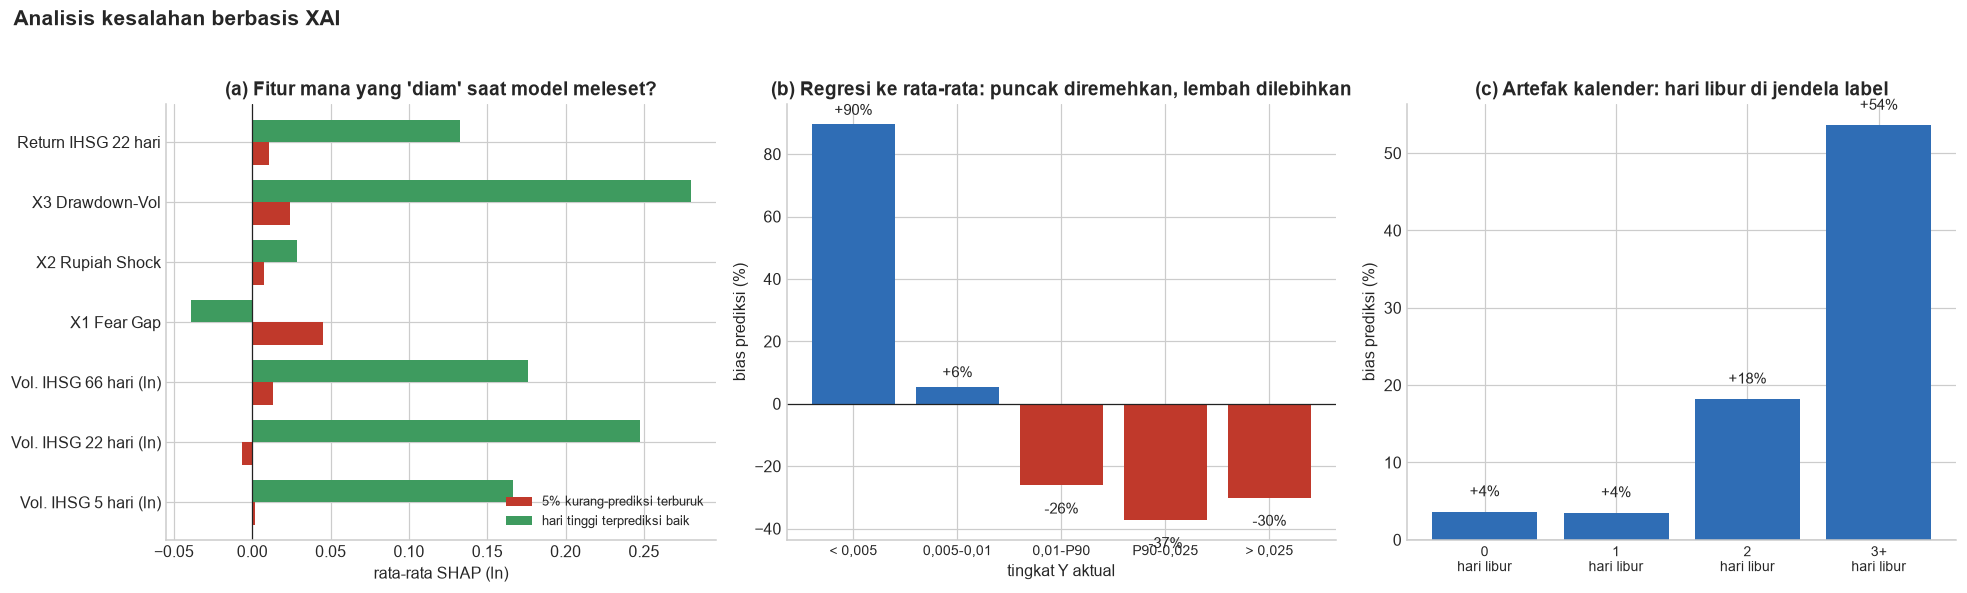

In [13]:
# (1) Kejutan dari kondisi tenang vs krisis yang diremehkan
calm = res["log_rv22"] < res["log_rv22"].median()
big_under = res["e"] > res["e"].quantile(0.95)
share_calm = (big_under & calm).sum() / big_under.sum() * 100
print(f"Dari {int(big_under.sum())} hari dengan kurang-prediksi terbesar (5% teratas), {share_calm:.0f}% terjadi ketika pasar sebelumnya tenang (kejutan), {100-share_calm:.0f}% ketika pasar sudah bergejolak (magnitudo diremehkan).")

# (2) Magnitudo: rasio aktual/prediksi pada tingkat Y berbeda
res["kelas_Y"] = pd.cut(res["y"], [0, 0.005, 0.01, P90, 0.025, 1], labels=["< 0,005", "0,005-0,01", "0,01-P90", "P90-0,025", "> 0,025"], include_lowest=True)
mag = res.groupby("kelas_Y", observed=True).agg(n=("y", "size"), rata2_aktual=("y", "mean"), rata2_prediksi=("p", "mean"))
mag["bias_%"] = (mag["rata2_prediksi"] / mag["rata2_aktual"] - 1) * 100
display(mag.style.format({"rata2_aktual": "{:.4f}", "rata2_prediksi": "{:.4f}", "bias_%": "{:+.0f}"}))

# (3) Artefak kalender: jendela dengan return = 0 (diketahui ex-post, hanya untuk analisi, bukan fitur)
zero_ret = (cal["IHSG"].pct_change() == 0).astype(float)
nz_win = zero_ret.rolling(5).sum().shift(-5).reindex(res.index).clip(upper=3)
cal_tbl = res.assign(nz=nz_win).groupby("nz").agg(n=("y", "size"), rata2_aktual=("y", "mean"), rata2_prediksi=("p", "mean"))
cal_tbl["bias_%"] = (cal_tbl["rata2_prediksi"] / cal_tbl["rata2_aktual"] - 1) * 100
cal_tbl.index = [f"{int(i)}{'+' if i == 3 else ''} hari libur di jendela" for i in cal_tbl.index]
display(cal_tbl.style.format({"rata2_aktual": "{:.4f}", "rata2_prediksi": "{:.4f}", "bias_%": "{:+.0f}"}))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ax = axes[0]
d_ = prof.iloc[:, :2].copy(); d_.columns = ["5% kurang-prediksi terburuk", "hari tinggi terprediksi baik"]
d_.plot.barh(ax=ax, color=[RED, GREEN], width=0.75); ax.axvline(0, color="#222", lw=0.8); ax.set_xlabel("rata-rata SHAP (ln)"); ax.set_title("(a) Fitur mana yang 'diam' saat model meleset?"); ax.legend(fontsize=8.5, loc="lower right")
ax = axes[1]
ax.bar(range(len(mag)), mag["bias_%"], color=[BLUE if v >= 0 else RED for v in mag["bias_%"]]); ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(range(len(mag))); ax.set_xticklabels(mag.index, fontsize=9); ax.set_xlabel("tingkat Y aktual"); ax.set_ylabel("bias prediksi (%)")
for i, v in enumerate(mag["bias_%"]): ax.text(i, v + (3 if v >= 0 else -9), f"{v:+.0f}%", ha="center", fontsize=9.5)
ax.set_title("(b) Regresi ke rata-rata: puncak diremehkan, lembah dilebihkan")
ax = axes[2]
ax.bar(range(len(cal_tbl)), cal_tbl["bias_%"], color=[BLUE if v >= 0 else RED for v in cal_tbl["bias_%"]]); ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(range(len(cal_tbl))); ax.set_xticklabels([i.replace(" hari libur di jendela", "\nhari libur") for i in cal_tbl.index], fontsize=9)
for i, v in enumerate(cal_tbl["bias_%"]): ax.text(i, v + 2, f"{v:+.0f}%", ha="center", fontsize=9.5)
ax.set_ylabel("bias prediksi (%)"); ax.set_title("(c) Artefak kalender: hari libur di jendela label")
fig.suptitle("Analisis kesalahan berbasis XAI", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.03)
plt.tight_layout(); save_fig(fig, "e_7.png"); plt.show()

>INTERPRETASI (SHAP *out-of-sample* dari model tiap fold; 26 hari volatilitas tinggi yang terprediksi baik, terutama Maret 2020, dipakai sebagai acuan.)

Temuan 1: kegagalan terbesar adalah kejutan dari pasar yang tenang, dan XAI menunjuk fitur yang "diam". Dari enam episode kurang-prediksi terbesar, empat (8 September 2020, 9 November 2016, 25 Januari 2021, 31 Agustus 2018) memiliki celah kontribusi terbesar pada X3 *Drawdown-Vol* (-0,31 sampai -0,36 pada skala ln, atau sekitar -27% sampai -30% pada prediksi). Pada kejadian-kejadian itu X3 bernilai -0,2 sampai -0,3: IHSG masih dekat puncak 60 harinya, dan volatilitas 22 hari (-4,48 sampai -5,04 pada skala ln) berada di bawah atau mendekati median sampel (-4,91). Misalnya, *"Model gagal memprediksi lonjakan pada 8 September 2020 (aktual 0,0329 vs prediksi 0,0077, kurang 4,25 kali) karena XAI menunjukkan X3 tidak berkontribusi (IHSG masih dekat puncak) dan struktur HAR tidak menyala (pasar sebelumnya tenang). Satu-satunya sinyal yang hidup adalah X1 (+1,9 simpangan baku), tetapi terlalu lemah."*

Temuan 2: profil kontribusi membedakan kegagalan dari keberhasilan. Pada 5% hari kurang-prediksi terburuk, kontribusi fitur "alarm" nyaris nol: volatilitas 22 hari -0,006, X3 +0,024, volatilitas 5 hari +0,002, dibanding +0,248, +0,280, dan +0,166 pada hari volatilitas tinggi yang terprediksi baik. X1 satu-satunya yang sedikit lebih positif pada hari-hari gagal (+0,045 vs -0,039): saluran ketakutan global memberi sinyal, tetapi tidak cukup kuat.

Temuan 3: dua jenis kegagalan, hampir seimbang. Dari 118 hari kurang-prediksi terbesar, 44% terjadi saat pasar sebelumnya tenang (kejutan yang tidak didahului turbulensi), dan 56% saat pasar sudah bergejolak (arah benar, magnitudo diremehkan). Contoh jenis kedua: 20 Maret 2020, prediksi 0,0358 vs aktual 0,0585 (1,63 kali), dengan X1 = +0,5, X2 = +3,1, X3 = -2,5: semua saluran menyala, namun puncaknya tetap diremehkan.

Temuan 4: regresi ke rata-rata memuluskan seluruh rentang (Gambar 6b). Bias prediksi menurut tingkat $Y$: +90% pada $Y<0{,}005$ (prediksi 0,0069 vs aktual 0,0036), +6% pada 0,005-0,01, -26% pada 0,01-P90, -37% pada P90-0,025, dan -30% pada $Y>0{,}025$. Model tidak pernah memprediksi nilai yang benar-benar rendah maupun yang benar-benar tinggi.

Temuan 5: artefak kalender menjelaskan sebagian *over-prediction*. Pada jendela dengan 2 hari libur bias +18%, dan dengan ≥ 3 hari libur +54% (n = 58), dibanding hanya +4% tanpa atau dengan satu hari libur. Ini tindak lanjut dari Notebook 2 dan Bagian 8C di Notebook 4: kesalahan tersebut bukan kegagalan membaca pasar, melainkan akibat kalender.

Implikasi bagi pengguna model. (i) Model dapat dipercaya sebagai peringatan atas turbulensi yang sedang atau mulai terbentuk, bukan sebagai peramal kejutan dari pasar tenang; (ii) nilai prediksi tidak boleh dibaca sebagai taksiran langsung puncak, melainkan sebagai penanda tingkat risiko; (iii) tambahan fitur harus menyasar kejutan dari kondisi tenang, misalnya sinyal likuiditas atau berita, yang berada di luar data yang tersedia pada lomba ini.

### ****8. Sistem Peringatan Dini (*Early Warning System*)****

Tujuan bisnis yang sebenarnya adalah **peringatan dini**, bukan prediksi angka. Karena model memprediksi volatilitas 5 hari **ke depan** dari informasi hari ini, setiap prediksi tinggi sudah merupakan peringatan lima hari sebelum gejolak terealisasi.

**Dua pelajaran yang membentuk rancangan.**
1. Model memuluskan puncak (Bagian 3 dan 7): ambang yang ditempatkan pada nilai $Y$ aktual (0,0149) tidak dapat dipakai pada nilai prediksi.
2. Ambang berbasis kuantil prediksi (mis. P90) bersifat relatif terhadap sampel latih. Pada rezim yang lebih bergejolak, ambang seperti itu menyalakan alarm pada mayoritas hari (dalam uji coba kami, 75% hari 2026 berstatus Merah), yang menimbulkan *alarm fatigue*.

Rancangan yang kami pilih: level berdasarkan probabilitas peristiwa yang terkalibrasi. Prediksi volatilitas diubah menjadi $P(Y>\text{P90}\mid\hat Y)$, yaitu peluang bahwa lima hari ke depan termasuk hari volatilitas tinggi nyata ($Y>0{,}0149$), dengan regresi logistik terhadap $\ln\hat Y$ yang di-*fit* **hanya pada prediksi *out-of-sample* CV 2016–2022**. Keuntungannya: (i) angkanya bermakna langsung bagi komite risiko ("peluang 40%"), (ii) kalibrasinya dapat diperiksa, dan (iii) ambang tidak bergantung pada rezim sampel.

| Level | Aturan | Makna operasional |
|---|---|---|
| 🟢 **Hijau** | peluang < 15% | kondisi normal |
| 🟡 **Kuning** | 15% ≤ peluang < 40% | waspada: tinjau eksposur dan likuiditas |
| 🔴 **Merah** | peluang ≥ 40% | risiko tinggi: tindakan mitigasi |

Ambang 15% dan 40% dipilih dari kurva *trade-off* presisi–*recall* pada CV (tabel di bawah), bukan dari *holdout* maupun data uji: 15% (sekitar 2 kali tingkat dasar peristiwa) menangkap setengah dari seluruh peristiwa, sedangkan 40% memberi presisi sekitar tiga perempat untuk peringatan paling serius.

,,n_peristiwa,AUC_ROC,AUC_PR
cakupan,model,,,
CV 2016-2022,Final: LightGBM,125,0.841,0.481
Holdout 2023-2024,Final: LightGBM,8,0.798,0.039
CV 2016-2022,Naif (rv5),125,0.739,0.368
Holdout 2023-2024,Naif (rv5),8,0.635,0.024
CV 2016-2022,HAR-OLS,125,0.771,0.361
Holdout 2023-2024,HAR-OLS,8,0.614,0.022
CV 2016-2022,GJR-GARCH,125,0.740,0.429
Holdout 2023-2024,GJR-GARCH,8,0.511,0.017


Tingkat dasar peristiwa (CV): 6.8% hari | tebakan acak: AUC-ROC 0,5 dan AUC-PR sekitar 0.07
Kalibrasi logistik: logit P = 17.68 + 4.33 ln(prediksi) | Brier CV = 0.0470 vs klimatologi 0.0638 (skill 26%)


desil,"(0.00166, 0.00903]","(0.00903, 0.0132]","(0.0132, 0.0177]","(0.0177, 0.023]","(0.023, 0.0301]","(0.0301, 0.0386]","(0.0386, 0.0511]","(0.0511, 0.0736]","(0.0736, 0.14]","(0.14, 0.968]"
prob_prediksi,0.006,0.011,0.015,0.020,0.026,0.034,0.044,0.061,0.098,0.366
frekuensi_nyata,0.000,0.005,0.011,0.027,0.033,0.027,0.044,0.109,0.066,0.361
n,183.000000,183.000000,182.000000,183.000000,182.000000,183.000000,182.000000,183.000000,182.000000,183.000000


Holdout: rata-rata probabilitas prediksi 2.2% vs frekuensi peristiwa nyata 1.5% (n peristiwa = 8)


,alarm_%_hari_CV,presisi_CV,recall_CV,alarm_%_hari_holdout
ambang_peluang,,,,
0.100000,14.2,0.28,0.58,2.1
0.150000,8.9,0.39,0.51,0.6
0.200000,7.1,0.45,0.46,0.2
0.250000,5.3,0.53,0.41,0.2
0.300000,4.2,0.60,0.37,0.0
0.400000,2.7,0.74,0.30,0.0
0.500000,2.3,0.79,0.26,0.0


Gambar disimpan: xLain-Lain/img/e_8.png


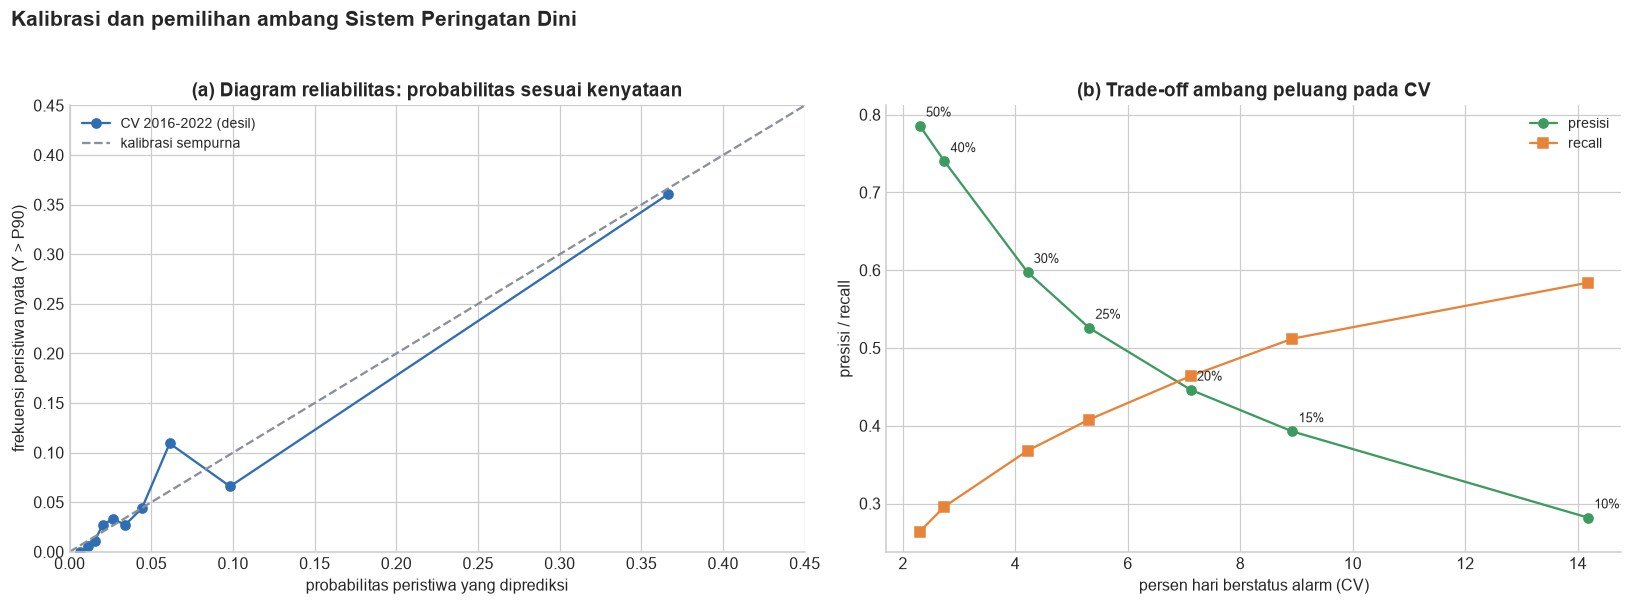

In [14]:
# DARI PREDIKSI KE PROBABILITAS PERISTIWA TERKALIBRASI
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
event = (yy > P90).astype(int)
def fit_calib(p):
    x = np.log(np.maximum(p.loc[cv_idx].to_numpy(), 1e-3)).reshape(-1, 1)
    return LogisticRegression(C=1e6, max_iter=1000).fit(x, event.loc[cv_idx])
def to_prob(lr, p):
    return pd.Series(lr.predict_proba(np.log(np.maximum(p.to_numpy(), 1e-3)).reshape(-1, 1))[:, 1], index=p.index)

# (i) Daya urut tanpa ambang: AUC-ROC dan AUC-PR tiap model
rows = []
for nm, p in MODELS.items():
    for scope, ix in [("CV 2016-2022", cv_idx), ("Holdout 2023-2024", ho_idx)]:
        ev_ = event.loc[ix]
        rows.append({"cakupan": scope, "model": nm, "n_peristiwa": int(ev_.sum()), "AUC_ROC": roc_auc_score(ev_, p.loc[ix]), "AUC_PR": average_precision_score(ev_, p.loc[ix])})
rank_tbl = pd.DataFrame(rows).set_index(["cakupan", "model"])
display(rank_tbl.style.format({"AUC_ROC": "{:.3f}", "AUC_PR": "{:.3f}"}))
base_rate = event.loc[cv_idx].mean()
print(f"Tingkat dasar peristiwa (CV): {base_rate*100:.1f}% hari | tebakan acak: AUC-ROC 0,5 dan AUC-PR sekitar {base_rate:.2f}")

# (ii) Kalibrasi probabilitas model final
lr_final = fit_calib(p_final)
pc, ph = to_prob(lr_final, p_final.loc[cv_idx]), to_prob(lr_final, p_final.loc[ho_idx])
b0, b1 = float(lr_final.intercept_[0]), float(lr_final.coef_[0, 0])
brier, brier_ref = brier_score_loss(event.loc[cv_idx], pc), base_rate * (1 - base_rate)
print(f"Kalibrasi logistik: logit P = {b0:.2f} + {b1:.2f} ln(prediksi) | Brier CV = {brier:.4f} vs klimatologi {brier_ref:.4f} (skill {(1-brier/brier_ref)*100:.0f}%)")
d_ = pd.DataFrame({"p": pc, "e": event.loc[cv_idx]}); d_["desil"] = pd.qcut(d_["p"], 10, duplicates="drop")
rel = d_.groupby("desil", observed=True).agg(prob_prediksi=("p", "mean"), frekuensi_nyata=("e", "mean"), n=("e", "size"))
display(rel.T.style.format("{:.3f}", subset=pd.IndexSlice[["prob_prediksi", "frekuensi_nyata"], :]))
print(f"Holdout: rata-rata probabilitas prediksi {ph.mean()*100:.1f}% vs frekuensi peristiwa nyata {event.loc[ho_idx].mean()*100:.1f}% (n peristiwa = {int(event.loc[ho_idx].sum())})")

# (iii) Kurva trade-off ambang pada CV (dasar pemilihan 15% dan 40%)
rows = []
for thr in (0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50):
    a = (pc >= thr).astype(int)
    rows.append({"ambang_peluang": thr, "alarm_%_hari_CV": a.mean() * 100, "presisi_CV": precision_score(event.loc[cv_idx], a, zero_division=0),
                 "recall_CV": recall_score(event.loc[cv_idx], a, zero_division=0), "alarm_%_hari_holdout": (ph >= thr).mean() * 100})
grid = pd.DataFrame(rows).set_index("ambang_peluang")
display(grid.style.format({"alarm_%_hari_CV": "{:.1f}", "presisi_CV": "{:.2f}", "recall_CV": "{:.2f}", "alarm_%_hari_holdout": "{:.1f}"}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.3))
ax = axes[0]
ax.plot(rel["prob_prediksi"], rel["frekuensi_nyata"], "o-", color=BLUE, label="CV 2016-2022 (desil)")
ax.plot([0, 0.5], [0, 0.5], "--", color=GREY, label="kalibrasi sempurna"); ax.set_xlim(0, 0.45); ax.set_ylim(0, 0.45)
ax.set_xlabel("probabilitas peristiwa yang diprediksi"); ax.set_ylabel("frekuensi peristiwa nyata (Y > P90)"); ax.set_title("(a) Diagram reliabilitas: probabilitas sesuai kenyataan"); ax.legend(fontsize=9)
ax = axes[1]
ax.plot(grid["alarm_%_hari_CV"], grid["presisi_CV"], "o-", color=GREEN, label="presisi"); ax.plot(grid["alarm_%_hari_CV"], grid["recall_CV"], "s-", color=ORANGE, label="recall")
for thr, r in grid.iterrows(): ax.annotate(f"{thr:.0%}", (r["alarm_%_hari_CV"], r["presisi_CV"]), textcoords="offset points", xytext=(4, 6), fontsize=8.5)
ax.set_xlabel("persen hari berstatus alarm (CV)"); ax.set_ylabel("presisi / recall"); ax.set_title("(b) Trade-off ambang peluang pada CV"); ax.legend(fontsize=9)
fig.suptitle("Kalibrasi dan pemilihan ambang Sistem Peringatan Dini", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.03)
plt.tight_layout(); save_fig(fig, "e_8.png"); plt.show()

Padanan pada skala prediksi: Kuning >= 0.0113, Merah >= 0.0153


,n_hari,n_peristiwa,hari_Merah,hari_Kuning,recall_Merah,presisi_Merah,recall_Kuning+,presisi_Kuning+
fold,,,,,,,,
CV2016,261,13,0,12,0.00,-,0.08,0.08
CV2017,260,0,0,0,-,-,-,-
CV2018,261,26,2,46,0.04,0.50,0.54,0.29
CV2019,261,2,0,3,0.00,-,0.00,0.00
CV2020,262,72,46,40,0.50,0.78,0.68,0.57
CV2021,261,5,0,6,0.00,-,0.00,0.00
CV2022,260,7,2,6,0.00,0.00,0.00,0.00
Holdout 2023-2024,517,8,0,3,0.00,-,0.00,0.00


CV agregat, level Merah: alarm 2.7% hari | presisi 0.74 | recall 0.30
CV agregat, level Kuning atau Merah: alarm 8.9% hari | presisi 0.39 | recall 0.51

Distribusi level pada 359 hari uji: {'Hijau': 238, 'Kuning': 64, 'Merah': 57} | persen Merah: 15.9 %
Persen hari Merah per tahun: {2025: 5.8, 2026: 41.6} | persen Kuning atau Merah: {2025: 17.4, 2026: 75.2}


mulai,selesai,hari_Merah,prediksi_maks,peluang_maks,tanggal_puncak,hari_jendela_Idulfitri
2025-02-27,2025-03-04,4,0.0203,69%,2025-02-28,0
2025-03-19,2025-03-27,6,0.0199,67%,2025-03-24,5
2025-04-08,2025-04-14,5,0.0303,93%,2025-04-08,0
2026-02-02,2026-02-12,7,0.0208,71%,2026-02-06,0
2026-03-04,2026-04-07,25,0.0279,90%,2026-03-27,6
2026-05-11,2026-05-22,10,0.0285,91%,2026-05-21,0


Gambar disimpan: xLain-Lain/img/e_9.png


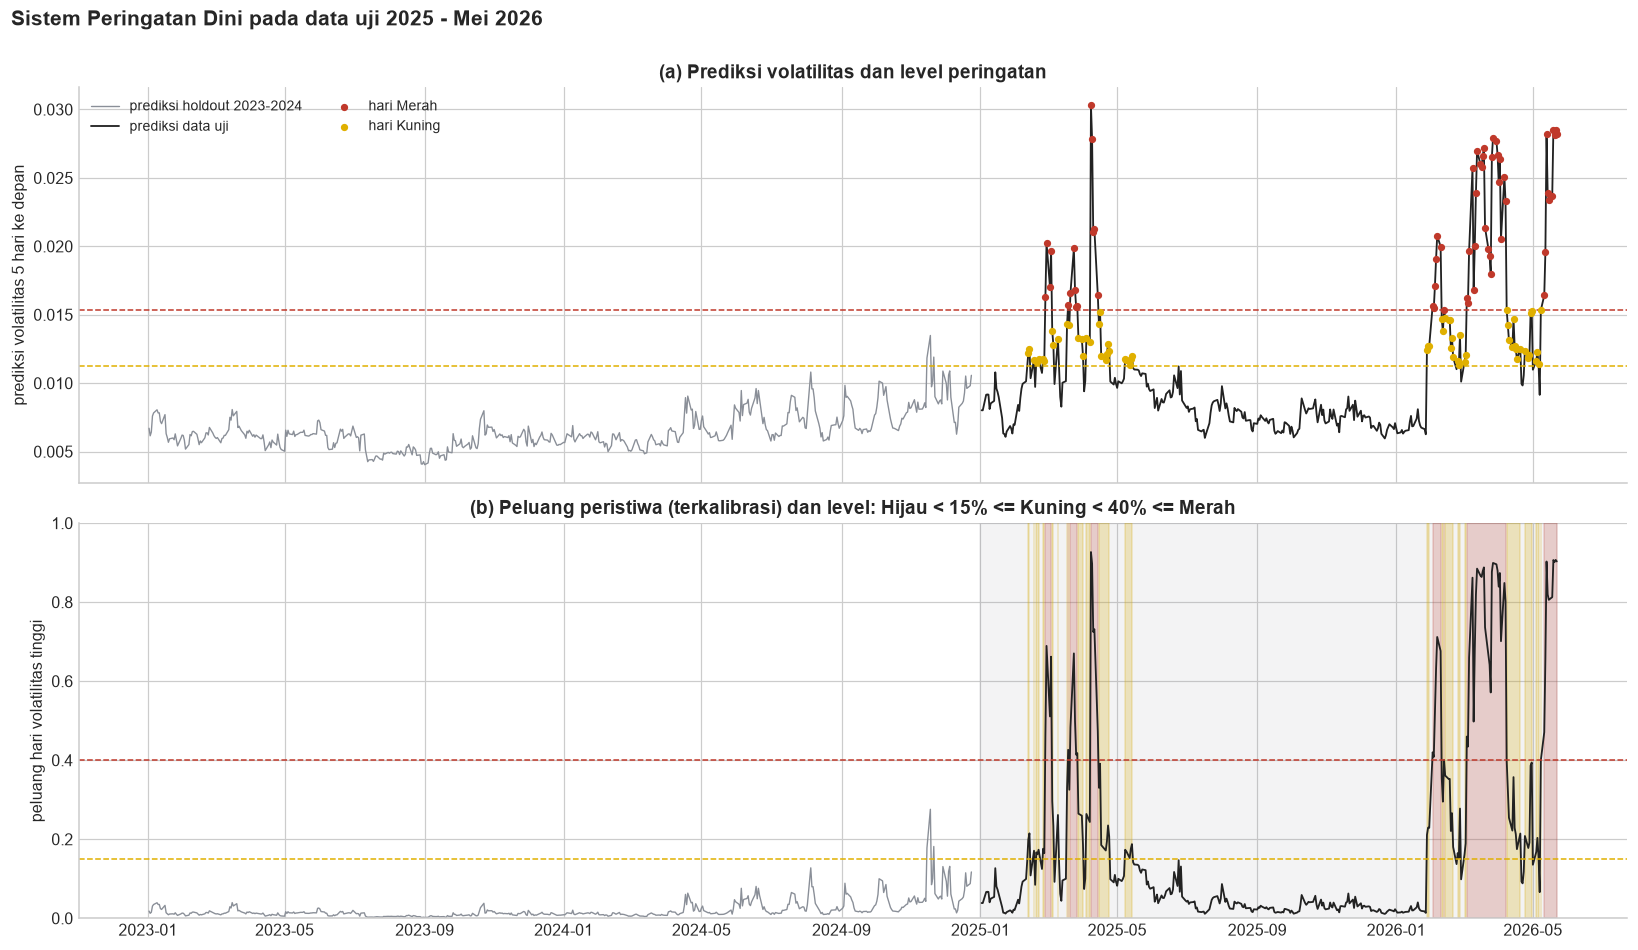


Tersimpan: Dataset/Clean/predictions_test.csv (Prediksi_Y, Jendela_Idulfitri, Prob_Peristiwa, Level_EWS)


In [15]:
# LEVEL HIJAU/KUNING/MERAH: CV, HOLDOUT, DAN DATA UJI
P_KUNING, P_MERAH = 0.15, 0.40
yhat_at = lambda p_: float(np.exp((np.log(p_ / (1 - p_)) - b0) / b1))
T75, T90 = yhat_at(P_KUNING), yhat_at(P_MERAH)  # padanan ambang pada skala prediksi volatilitas
print(f"Padanan pada skala prediksi: Kuning >= {T75:.4f}, Merah >= {T90:.4f}")
lvl = lambda pr_: pd.Series(np.where(pr_ >= P_MERAH, "Merah", np.where(pr_ >= P_KUNING, "Kuning", "Hijau")), index=pr_.index)

rows = []
for f in folds + [holdout]:
    ix = f["val"]; pr_ = to_prob(lr_final, p_final.loc[ix]); L = lvl(pr_); ev_ = event.loc[ix]
    rows.append({"fold": f["name"], "n_hari": len(ix), "n_peristiwa": int(ev_.sum()), "hari_Merah": int((L == "Merah").sum()), "hari_Kuning": int((L == "Kuning").sum()),
                 "recall_Merah": recall_score(ev_, (L == "Merah").astype(int), zero_division=0) if ev_.sum() else np.nan,
                 "presisi_Merah": precision_score(ev_, (L == "Merah").astype(int), zero_division=0) if (L == "Merah").sum() else np.nan,
                 "recall_Kuning+": recall_score(ev_, (L != "Hijau").astype(int), zero_division=0) if ev_.sum() else np.nan,
                 "presisi_Kuning+": precision_score(ev_, (L != "Hijau").astype(int), zero_division=0) if (L != "Hijau").sum() else np.nan})
fold_ews = pd.DataFrame(rows).set_index("fold")
display(fold_ews.style.format({c: "{:.2f}" for c in fold_ews.columns if "recall" in c or "presisi" in c}, na_rep="-"))
Lcv = lvl(pc); evcv = event.loc[cv_idx]
for nm, mask_ in [("Merah", Lcv == "Merah"), ("Kuning atau Merah", Lcv != "Hijau")]:
    print(f"CV agregat, level {nm}: alarm {mask_.mean()*100:.1f}% hari | presisi {precision_score(evcv, mask_.astype(int)):.2f} | recall {recall_score(evcv, mask_.astype(int)):.2f}")

# ---- Data uji ----
pt = pd.read_csv(CLEAN_DIR / "predictions_test.csv", parse_dates=["Date"]).set_index("Date")["Prediksi_Y"]
assert len(pt) == len(test_idx)
pr = to_prob(lr_final, pt); level = lvl(pr).rename("Level_EWS")
cnt = level.value_counts().reindex(["Hijau", "Kuning", "Merah"]).fillna(0).astype(int)
print("\nDistribusi level pada 359 hari uji:", cnt.to_dict(), "| persen Merah:", round(cnt['Merah'] / len(level) * 100, 1), "%")
print("Persen hari Merah per tahun:", (level.eq("Merah").groupby(level.index.year).mean() * 100).round(1).to_dict(), "| persen Kuning atau Merah:", (level.ne("Hijau").groupby(level.index.year).mean() * 100).round(1).to_dict())

red = level[level == "Merah"].index
episodes, start, prev = [], None, None
for d in red:
    if start is None: start = prev = d
    elif (d - prev).days <= 5: prev = d
    else: episodes.append((start, prev)); start = prev = d
if start is not None: episodes.append((start, prev))
ep = pd.DataFrame([{"mulai": a.date(), "selesai": b.date(), "hari_Merah": int(((red >= a) & (red <= b)).sum()), "prediksi_maks": float(pt.loc[a:b].max()), "peluang_maks": float(pr.loc[a:b].max()),
                    "tanggal_puncak": pt.loc[a:b].idxmax().date(), "hari_jendela_Idulfitri": int(F.loc[a:b, "idf_in_next5"].sum())} for a, b in episodes])
display(ep.style.hide(axis="index").format({"prediksi_maks": "{:.4f}", "peluang_maks": "{:.0%}"}))

fig, axes = plt.subplots(2, 1, figsize=(15, 8.6), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
ax = axes[0]
ph_ = p_final.loc[ho_idx]
ax.plot(ph_.index, ph_.values, color=GREY, lw=0.9, label="prediksi holdout 2023-2024"); ax.plot(pt.index, pt.values, color="#222", lw=1.2, label="prediksi data uji")
for l_, col in [("Merah", RED), ("Kuning", YELLOW)]:
    s_ = pt[level == l_]; ax.scatter(s_.index, s_.values, s=14, color=col, zorder=4, label=f"hari {l_}")
ax.axhline(T90, color=RED, ls="--", lw=1); ax.axhline(T75, color=YELLOW, ls="--", lw=1)
ax.set_ylabel("prediksi volatilitas 5 hari ke depan"); ax.set_title("(a) Prediksi volatilitas dan level peringatan"); ax.legend(loc="upper left", fontsize=9, ncol=2)
ax = axes[1]
pr_h = to_prob(lr_final, ph_)
ax.plot(pr_h.index, pr_h.values, color=GREY, lw=0.9); ax.plot(pr.index, pr.values, color="#222", lw=1.2)
ax.fill_between(pr.index, 0, 1, where=(pr >= P_MERAH).values, color=RED, alpha=0.22, step="mid"); ax.fill_between(pr.index, 0, 1, where=((pr >= P_KUNING) & (pr < P_MERAH)).values, color=YELLOW, alpha=0.25, step="mid")
ax.axhline(P_MERAH, color=RED, ls="--", lw=1); ax.axhline(P_KUNING, color=YELLOW, ls="--", lw=1); ax.set_ylim(0, 1)
ax.set_ylabel("peluang hari volatilitas tinggi"); ax.set_title("(b) Peluang peristiwa (terkalibrasi) dan level: Hijau < 15% <= Kuning < 40% <= Merah"); ax.axvspan(TEST_START, raw.index.max(), color=GREY, alpha=0.10)
fig.suptitle("Sistem Peringatan Dini pada data uji 2025 - Mei 2026", x=0.01, ha="left", fontweight="bold", fontsize=13.5, y=1.0)
plt.tight_layout(); save_fig(fig, "e_9.png"); plt.show()

out = pd.read_csv(CLEAN_DIR / "predictions_test.csv", parse_dates=["Date"]).set_index("Date")
out = out.drop(columns=[c for c in ("Level", "Level_EWS", "Prob_Peristiwa") if c in out.columns])
out["Prob_Peristiwa"] = pr.round(4); out["Level_EWS"] = level
out.reset_index().to_csv(CLEAN_DIR / "predictions_test.csv", index=False)
print("\nTersimpan: Dataset/Clean/predictions_test.csv (Prediksi_Y, Jendela_Idulfitri, Prob_Peristiwa, Level_EWS)")

>INTERPRETASI

1. **Probabilitas terkalibrasi dengan sangat baik.** Skor Brier 0,0470 vs 0,0638 untuk prediksi klimatologi (*skill* **26%**). Pada desil prediksi tertinggi, peluang yang diprediksi **36,6%** sedangkan frekuensi nyata **36,1%**; pada desil-desil lain selisihnya kecil (Gambar e_8). Pada *holdout*, rata-rata peluang yang diprediksi 2,2% vs frekuensi nyata 1,5%: sedikit berlebih tetapi dalam orde yang benar.

2. **Daya urut mengalahkan semua pembanding.** AUC-ROC pada CV **0,841** (naif 0,739; HAR 0,771; GJR-GARCH 0,740) dan AUC-PR **0,481** (naif 0,368; HAR 0,361; GJR 0,429; tebakan acak 0,07). Pada *holdout* AUC-ROC 0,798 vs 0,635; 0,614; 0,511, tetapi hanya 8 peristiwa sehingga angka ini tidak kami andalkan.

3. **Titik operasi (CV).** Ambang **15% (Kuning)**: 8,9% hari berstatus alarm, presisi **0,39**, *recall* **0,51**, artinya hampir 4 dari 10 alarm benar dan setengah dari seluruh peristiwa tertangkap, pada tingkat dasar peristiwa hanya 6,8%. Ambang **40% (Merah)**: hanya 2,7% hari, presisi **0,74**, *recall* 0,30.

4. **Kinerja sangat bergantung rezim, dan ini kami nyatakan.** Pada fold krisis **2020**, Merah memiliki presisi **0,78** dan *recall* **0,50**, dan Kuning+Merah *recall* 0,68. Pada 2018, Kuning+Merah menangkap 54% peristiwa. Namun pada fold tenang (2016, 2019, 2021, 2022) hampir tidak ada peristiwa yang tertangkap, dan pada ***holdout* 2023–2024 tidak ada hari Merah** serta ketiga hari Kuning tidak menangkap satu pun dari delapan peristiwa. Ini konsisten dengan analisis kesalahan: lonjakan kecil dari pasar tenang tidak terdeteksi. Sistem ini efektif sebagai peringatan atas **gejolak yang sedang terbentuk**, bukan atas kejutan.

5. **Penerapan pada data uji.** Dari 359 hari: **57 hari Merah (15,9%)**, 64 Kuning, dan 238 Hijau. Menurut tahun: 2025 hanya 5,8% Merah (17,4% Kuning atau Merah), sedangkan **2026 41,6% Merah (75,2% Kuning atau Merah)**, sejalan dengan rezim yang jauh lebih bergejolak (Notebook 2). Enam episode Merah: **27 Feb - 4 Mar 2025** (puncak peluang 69%), **19-27 Mar 2025** (67%), **8-14 Apr 2025** (puncak 0,0303; peluang 93%), **2-12 Feb 2026** (71%), **4 Mar - 7 Apr 2026** (25 hari; puncak 0,0279; 90%), dan **11–22 Mei 2026** (puncak 0,0285; 91%).

6. **Dua catatan kehati-hatian untuk pembaca hasil.** (i) Episode **19–27 Maret 2025** memuat 5 hari yang berada pada jendela Idulfitri; pada jendela seperti itu model secara historis cenderung terlalu tinggi (bias +0,0035), sehingga episode ini dibaca sebagai peringatan yang kemungkinan terlalu waspada. (ii) Ambang 15% dan 40% dipilih dari CV dan dipakai tanpa perubahan pada *holdout* dan data uji, sehingga tidak ada penyetelan ambang terhadap data uji.

7. **Cara penggunaan yang kami usulkan bagi PT Investion**: **Hijau**, pemantauan rutin; **Kuning**, tinjau eksposur dan *buffer* likuiditas serta siapkan rencana mitigasi; **Merah**, jalankan mitigasi (mis. pengurangan eksposur atau lindung nilai) dan tinjau harian. Rekomendasi ini bersifat ilustratif; besaran tindakan harus ditetapkan komite risiko sesuai toleransi risiko perusahaan.

### ****9. Ringkasan Hasil dan Kesimpulan****

In [16]:
# ============================================================
# Ringkasan Angka Kunci
# ============================================================
cvm, hom = metrics(yy.loc[cv_idx], p_final.loc[cv_idx]), metrics(yy.loc[ho_idx], p_final.loc[ho_idx])
nvc, nvh = metrics(yy.loc[cv_idx], p_naive.loc[cv_idx]), metrics(yy.loc[ho_idx], p_naive.loc[ho_idx])
hrc, hrh = metrics(yy.loc[cv_idx], p_har.loc[cv_idx]), metrics(yy.loc[ho_idx], p_har.loc[ho_idx])
gjc, gjh = metrics(yy.loc[cv_idx], p_gjr.loc[cv_idx]), metrics(yy.loc[ho_idx], p_gjr.loc[ho_idx])
summary = pd.Series({
    "RMSE_CV_final": cvm["RMSE"], "RMSE_CV_naif": nvc["RMSE"], "RMSE_CV_HAR": hrc["RMSE"], "RMSE_CV_GJR": gjc["RMSE"],
    "MAE_CV_final": cvm["MAE"], "MAE_CV_naif": nvc["MAE"],
    "RMSE_holdout_final": hom["RMSE"], "RMSE_holdout_naif": nvh["RMSE"], "RMSE_holdout_HAR": hrh["RMSE"], "RMSE_holdout_GJR": gjh["RMSE"],
    "MAE_holdout_final": hom["MAE"], "MAE_holdout_naif": nvh["MAE"],
    "penurunan_RMSE_vs_naif_CV_%": (cvm["RMSE"] / nvc["RMSE"] - 1) * 100, "penurunan_RMSE_vs_naif_holdout_%": (hom["RMSE"] / nvh["RMSE"] - 1) * 100,
    "penurunan_RMSE_vs_HAR_CV_%": (cvm["RMSE"] / hrc["RMSE"] - 1) * 100, "penurunan_RMSE_vs_GJR_CV_%": (cvm["RMSE"] / gjc["RMSE"] - 1) * 100,
    "P90_Y_latih": P90, "ambang_Kuning_peluang": P_KUNING, "ambang_Merah_peluang": P_MERAH, "ambang_Kuning_prediksi": T75, "ambang_Merah_prediksi": T90, "Brier_skill_%": (1 - brier / brier_ref) * 100,
    "hari_uji_Merah": int(cnt["Merah"]), "hari_uji_Kuning": int(cnt["Kuning"]), "hari_uji_Hijau": int(cnt["Hijau"]),
}, name="nilai")
summary.to_csv(NOTE_DIR / "ringkasan_hasil.csv")
display(summary.to_frame().style.format("{:.5f}"))

,nilai
RMSE_CV_final,0.00407
RMSE_CV_naif,0.00556
RMSE_CV_HAR,0.00472
RMSE_CV_GJR,0.00452
MAE_CV_final,0.00301
MAE_CV_naif,0.00398
RMSE_holdout_final,0.00311
RMSE_holdout_naif,0.00403
RMSE_holdout_HAR,0.00323
RMSE_holdout_GJR,0.00371


## ****KESIMPULAN TAHAP 5: EVALUATION****

**Yang dibuktikan**

| # | Klaim | Bukti |
|---|---|---|
| 1 | Model mengalahkan baseline naif | RMSE −26,8% (CV) dan −22,9% (*holdout*); CI *block bootstrap* seluruhnya < 1; DM $p<0{,}001$ |
| 2 | Mengalahkan GJR-GARCH | RMSE −10,0% (CV) dan −16,3% (*holdout*); $p<0{,}001$ |
| 3 | Keunggulan atas HAR nyata tetapi sedang | RMSE −13,8% (CV); signifikan pada MAE ($p=0{,}028$), borderline pada RMSE ($p=0{,}070$) |
| 4 | Prediksi terkalibrasi | Kemiringan Mincer–Zarnowitz 0,976 pada CV; probabilitas peristiwa: Brier *skill* 26% |
| 5 | Penjelasan eksak dan sesuai teori | *Additivity* $10^{-14}$; X1, X2, X3 semuanya berpengaruh searah teori; X1–X3 menyumbang sekitar 40% penjelasan |
| 6 | Kegagalan model dipahami lewat XAI | Empat dari enam kegagalan terbesar adalah kejutan dari pasar tenang, ketika X3 dan struktur HAR "diam" |
| 7 | Peringatan dini yang dapat dipakai | Merah: presisi 0,74; Kuning+: *recall* 0,51; AUC-ROC 0,841 vs 0,74-0,77 |

**Keterbatasan yang kami nyatakan terbuka**

1. Kinerja pada data uji 2025–2026 tidak dapat diukur (tidak ada $Y$); seluruh klaim kinerja berasal dari CV dan *holdout*.
2. Peringkat individual antar fitur volatilitas tidak stabil (korelasi peringkat antar fold 0,62; SHAP vs *permutation* 0,25). Yang stabil adalah arah pengaruh dan porsi grup (X1–X3 sekitar 40%).
3. Model tidak mendeteksi kejutan dari pasar tenang dan memuluskan puncak (bias -26% sampai -37% pada hari volatilitas tinggi).
4. Pada *holdout* tenang, sistem peringatan tidak menangkap satu pun dari 8 peristiwa; efektivitasnya terbukti pada rezim bergejolak (2020).
5. Keunggulan terhadap HAR-OLS sedang, dan borderline pada RMSE.

---